# FINANCE & ECONOMICS TIME-SERIES ANALYSIS
## Final Integrated Project | NYU Data Science Bootcamp

**Team integration:** Aiden Yang · Hanwen Li · Ray Duan  
**Dataset:** Finance & Economics Dataset (2000–2008)  
**Deliverable:** An executable, auditable research notebook with EDA, preprocessing, features, VAR/LSTM/GRU forecasts, MAE/RMSE/MAPE comparisons and professional figures.

> **Research validity notice:** The supplied financial CSV contains implausible weekend stock-index observations and abrupt macroeconomic changes. Its original production process is *not verified*. Treat these results as **synthetic-like data workflow experiments**, not as validated historical forecasts or economic guidance.

### Reproduction
Unzip the full project package. Keep this notebook beside the `data/`, `src/`, `figures/` and `results/` directories; install the packages in `requirements.txt`, then choose **Run All**. The source code in `src/project_pipeline.py` is written to be modular and directly inspectable. The saved output in this notebook was executed with the provided CSV.

## Roadmap and alignment with the Project Targets
| Target requirement | This notebook | Output |
|---|---|---|
| Dataset Exploration | §§ 1–2 | Audit tables + anomaly charts |
| Data Cleaning & Preprocessing | § 3 | Full-month aligned data + observed-stock table |
| EDA | § 4 | Trend, distribution, seasonality, correlation, CCF charts |
| Feature Engineering | § 5 | Past-only lag, moving average, volatility, spread features |
| Forecasting | § 6 | Baselines, Ridge, Random Forest, VAR, LSTM, GRU |
| Evaluation | § 7 | 18-month chronological test, MAE/RMSE/MAPE/sMAPE |
| Insights & visualization | §§ 7–9 | Forecast plots, illustrative intervals, conclusions |
| Optional interface | External `dashboard.py` | Optional Streamlit results explorer |

**Scope:** Two target series are evaluated: monthly descriptive median **Inflation Rate (%)** and **Unemployment Rate (%)**. Neither is represented as an official published monthly series.

# 1. Setup and audit trail
Every run reads the **unchanged original CSV**. The two copies supplied by Aiden and Ray are byte-for-byte identical, so the project keeps only one canonical input. Each team member's original work is also preserved under `sources/`.

**Reproducibility safeguards:** fixed random seed; split before fitting scalers; no random train/test split; no future-month values in lagged predictors.

In [ ]:
import sys, json
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'src'/'project_pipeline.py').exists() and (PROJECT_ROOT.parent/'src'/'project_pipeline.py').exists():
    PROJECT_ROOT=PROJECT_ROOT.parent
if not (PROJECT_ROOT/'src'/'project_pipeline.py').exists():
    raise FileNotFoundError('Open this notebook from inside the unzipped Financial_Economics_Final_Project folder.')
sys.path.insert(0,str(PROJECT_ROOT))
from src.project_pipeline import (DATA,FIG,OUT,MACRO,MODELING,TARGETS,
     quality_exploration,build_monthly,engineer_features,
     plot_exploration,plot_eda,plot_features,
     model_forecasts,plot_model_outputs)
raw=pd.read_csv(DATA)
print('Canonical data file:',DATA)
print('Raw shape:',raw.shape)
display(raw.head(4))

Canonical data file: /mnt/data/Financial_Economics_Final_Project/data/finance_economics_dataset.csv
Raw shape: (3000, 24)


,Date,Stock Index,Open Price,Close Price,Daily High,Daily Low,Trading Volume,GDP Growth (%),Inflation Rate (%),Unemployment Rate (%),Interest Rate (%),Consumer Confidence Index,Government Debt (Billion USD),Corporate Profits (Billion USD),Forex USD/EUR,Forex USD/JPY,Crude Oil Price (USD per Barrel),Gold Price (USD per Ounce),Real Estate Index,Retail Sales (Billion USD),Bankruptcy Rate (%),Mergers & Acquisitions Deals,Venture Capital Funding (Billion USD),Consumer Spending (Billion USD)
0,2000-01-01,Dow Jones,2128.75,2138.48,2143.70,2100.55,2670411,-0.37,6.06,6.10,6.06,114,27271,1645,1.04,119.87,47.20,1052.34,390.23,2229,2.12,3,76.64,4589
1,2000-01-02,S&P 500,2046.82,2036.18,2082.83,2009.53,690220415,3.19,4.95,6.62,2.19,101,16160,1008,1.00,98.22,52.84,1957.73,346.23,4156,1.40,21,5.67,10101
2,2000-01-03,Dow Jones,1987.92,1985.26,2022.28,1978.37,315284661,5.54,9.13,2.60,0.82,92,29962,4562,0.83,80.13,78.80,2339.49,439.46,340,0.79,48,39.43,13665
3,2000-01-04,Dow Jones,4625.02,4660.47,4665.26,4595.46,13098297,10.00,3.77,2.20,3.71,112,12745,4183,0.95,149.15,28.18,1308.54,213.07,8456,4.22,16,12.83,5192


# 2. Dataset exploration / provenance and quality

**Questions:** What is the observation unit? Which indicators are included? Are rows complete? Are dates plausible for US index trading? Do standard outlier rules catch the temporal anomalies?

**Tests:** date uniqueness, weekend flags, missing cells, OHLC inequalities, IQR limits, consecutive-record jumps. A value can be inside the overall IQR distribution and still jump unnaturally from one day to the next.

In [ ]:
df, audit = quality_exploration(raw)
display(pd.DataFrame({'metric': ['rows','columns','numeric variables','missing cells','duplicate rows','duplicate dates','weekend rows','invalid OHLC','IQR flags'],
                      'value':[audit['original_rows'],audit['original_columns'],audit['numerical_columns'],audit['missing_cells'],audit['duplicate_rows'],audit['duplicate_dates'],audit['weekend_records'],audit['invalid_ohlc_rows'],audit['iqr_outliers_total']]}))
print('Date range:',audit['date_start'],'to',audit['date_end'])
print('Index counts:',audit['index_counts'])
print('Temporal jump flags:',audit['temporal_jump_counts'])

,metric,value
0,rows,3000
1,columns,24
2,numeric variables,22
3,missing cells,0
4,duplicate rows,0
5,duplicate dates,0
6,weekend rows,858
7,invalid OHLC,0
8,IQR flags,0


Date range: 2000-01-01 to 2008-03-18
Index counts: {'S&P 500': 1036, 'NASDAQ': 1007, 'Dow Jones': 957}
Temporal jump flags: {'GDP change >5 pp': 1285, 'Inflation change >3 pp': 1490, 'Debt change >$5,000B': 2096, 'Index-to-next-observation >20%': 2163}


### Interpretation
- **3,000 daily rows, 24 columns, zero missing cells and zero duplicate dates.** These are *structural* qualities, not proof of source credibility.
- **858 weekend rows (28.6%)** include nonzero trading volumes in a file labeled with major US stock indices.
- The index labels alternate by day: each date has one index observation, not simultaneous daily prices for all three indices.
- Temporal thresholds identify **1,285 large GDP changes**, **1,490 inflation changes**, **2,096 debt changes**, and **2,163 large between-observation index moves**. These counts are **screening flags**, not confirmed misprints.
- The source might be simulated or synthetic; **the exact original generation method is unverified**.

# 3. Cleaning and consistent monthly indexing

We preserve the raw file and create **two different analytical views**:

1. **Macroeconomic view:** Compute monthly descriptive medians. The original file is artificially daily for fields normally published on monthly or quarterly schedules, so these medians are *not official monthly economic releases*.
2. **Stock view:** Separate index labels, exclude weekends for the market-only descriptive table, and compute between-observation returns within each index. Do **not** invent missing prices with backward fills; irregular gaps remain visible.

**Important correction:** March 2008 contains only 18 days, so it must not be treated as a complete calendar month. The modeling table therefore uses **98 full calendar months (Jan 2000–Feb 2008)** rather than 99 months.

In [ ]:
monthly, market_obs, clean_info=build_monthly(df)
print('Cleaning report:',clean_info)
display(monthly[MACRO].head(5).round(2))
display(market_obs[['Date','Stock Index','Close Price','days_since_previous_observation','between_observation_return']].head(8))
print('Any missing monthly macro cells?',int(monthly[MACRO].isna().sum().sum()))

Cleaning report: {'complete_months': 98, 'dropped_partial_months': 1, 'last_included_month': '2008-02-01', 'last_dropped_month': '2008-03-01', 'market_weekday_observations': 2142}


,GDP Growth (%),Inflation Rate (%),Unemployment Rate (%),Interest Rate (%)
Date,,,,
2000-01-01,3.19,6.08,8.20,3.93
2000-02-01,0.93,6.11,9.20,4.72
2000-03-01,2.44,5.06,10.47,6.79
2000-04-01,1.74,7.06,8.68,5.00
2000-05-01,1.06,3.88,6.78,5.38


,Date,Stock Index,Close Price,days_since_previous_observation,between_observation_return
2,2000-01-03,Dow Jones,1985.26,NaN,NaN
3,2000-01-04,Dow Jones,4660.47,1.0,1.347536
6,2000-01-07,Dow Jones,3996.40,3.0,-0.142490
9,2000-01-10,Dow Jones,1229.64,3.0,-0.692313
10,2000-01-11,Dow Jones,2943.31,1.0,1.393636
11,2000-01-12,Dow Jones,1101.00,1.0,-0.625931
13,2000-01-14,Dow Jones,4629.28,2.0,3.204614
27,2000-01-28,Dow Jones,3899.17,14.0,-0.157716


Any missing monthly macro cells? 0


In [ ]:
plot_exploration(df,audit,monthly,market_obs)
print('Quality and market inspection images exported to figures/.')

Quality and market inspection images exported to figures/.


**Figure: Date coverage and index sampling**

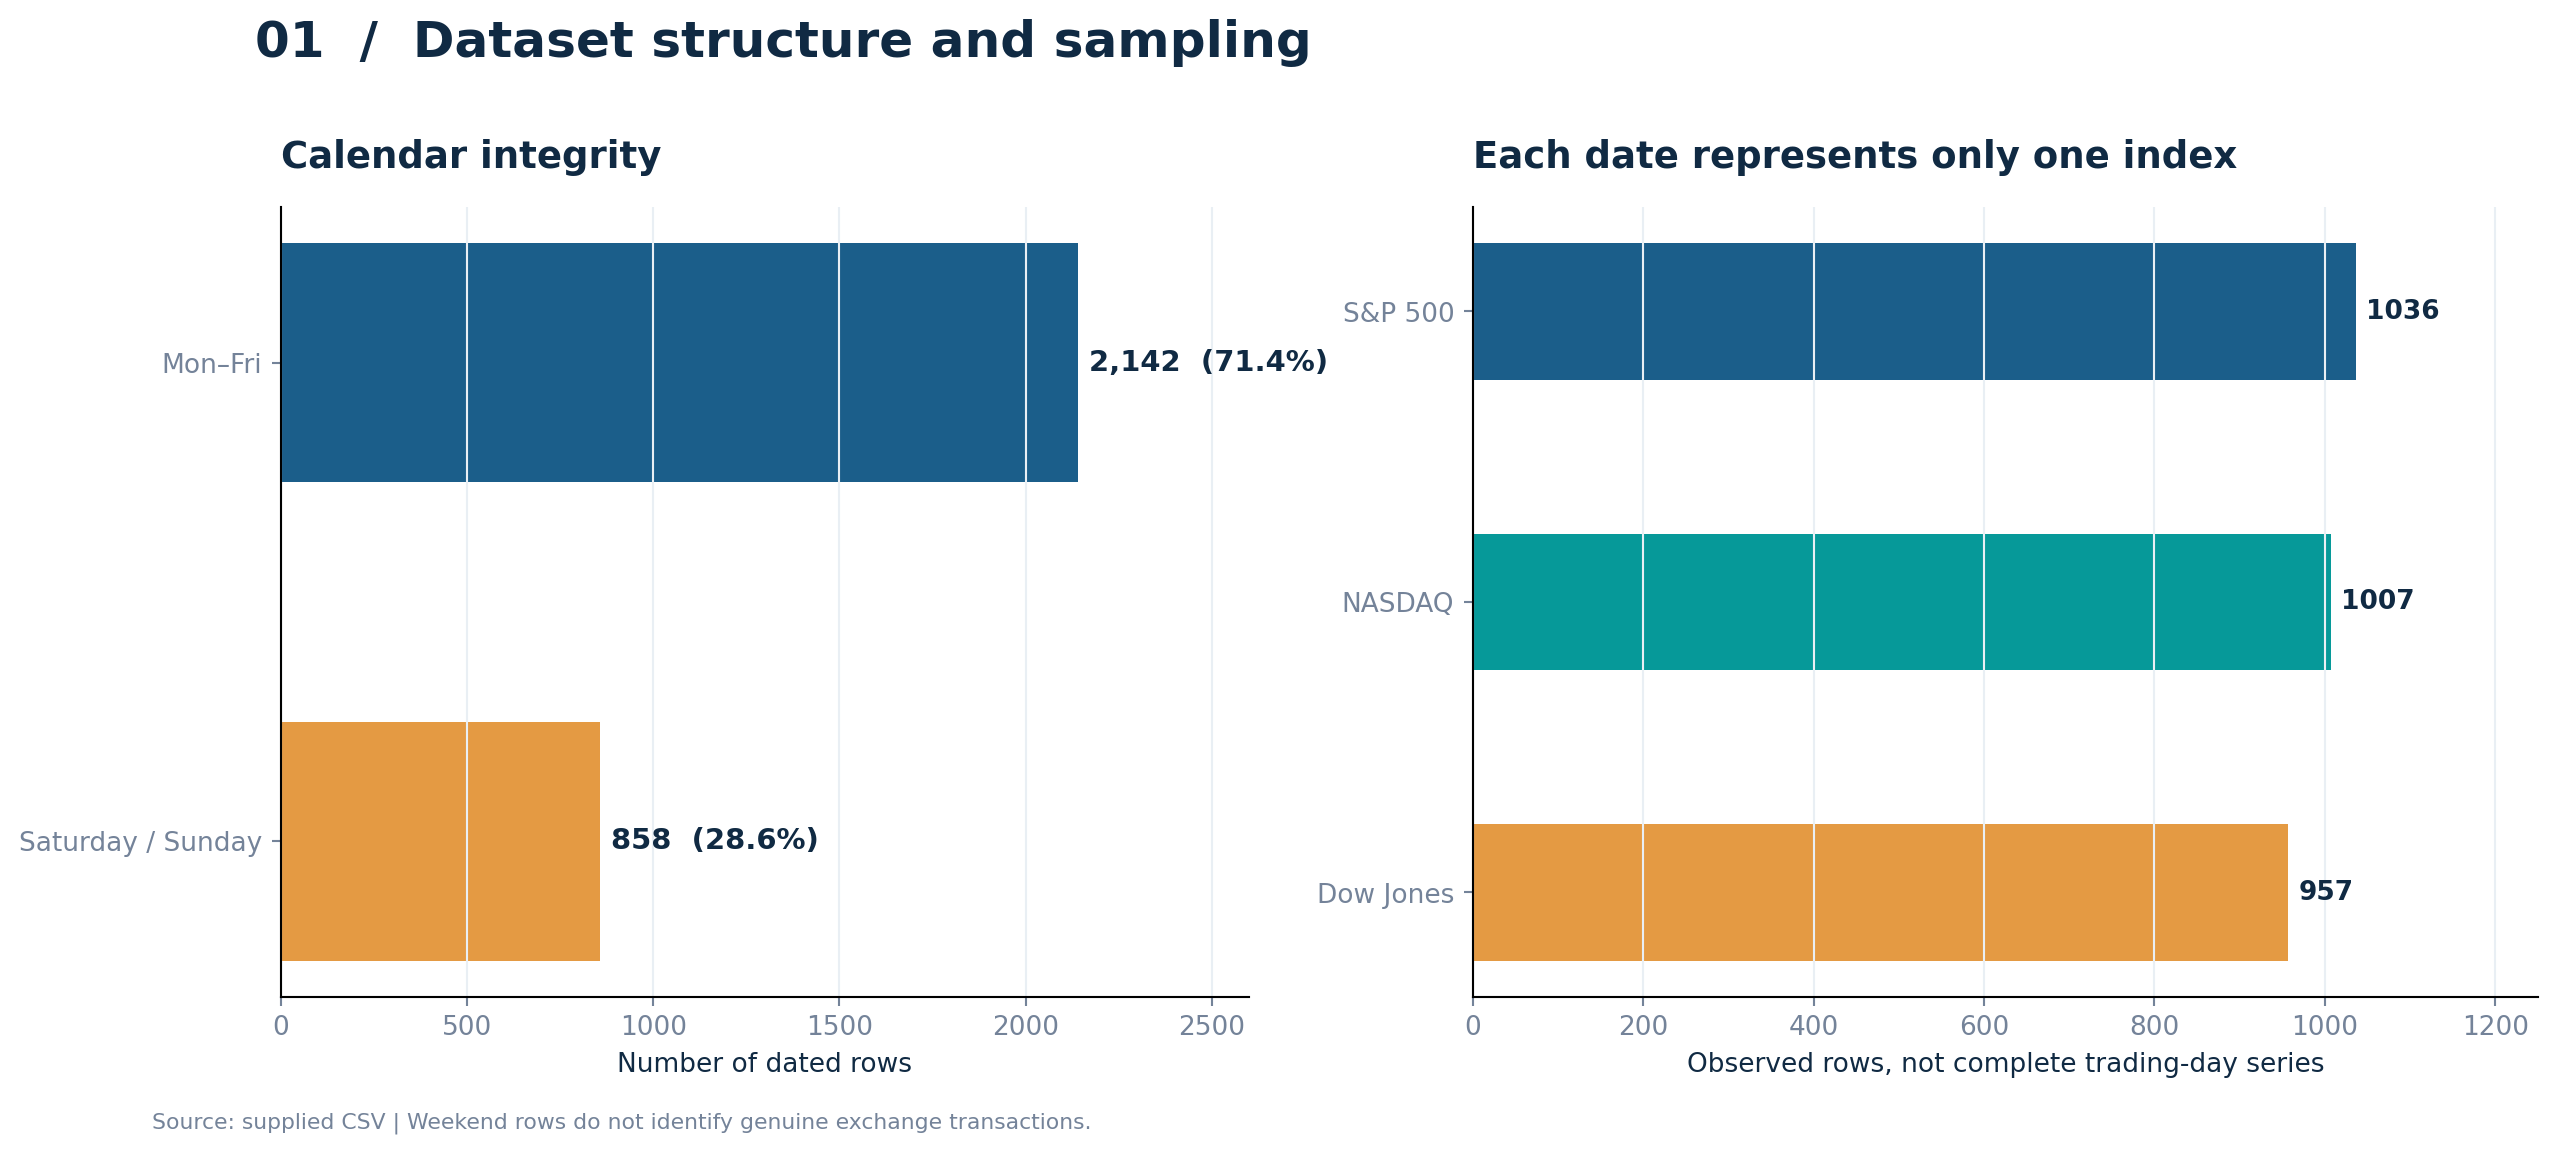

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "01_structure_and_weekends.png")))

**Figure: Counts of temporal anomaly screening flags**

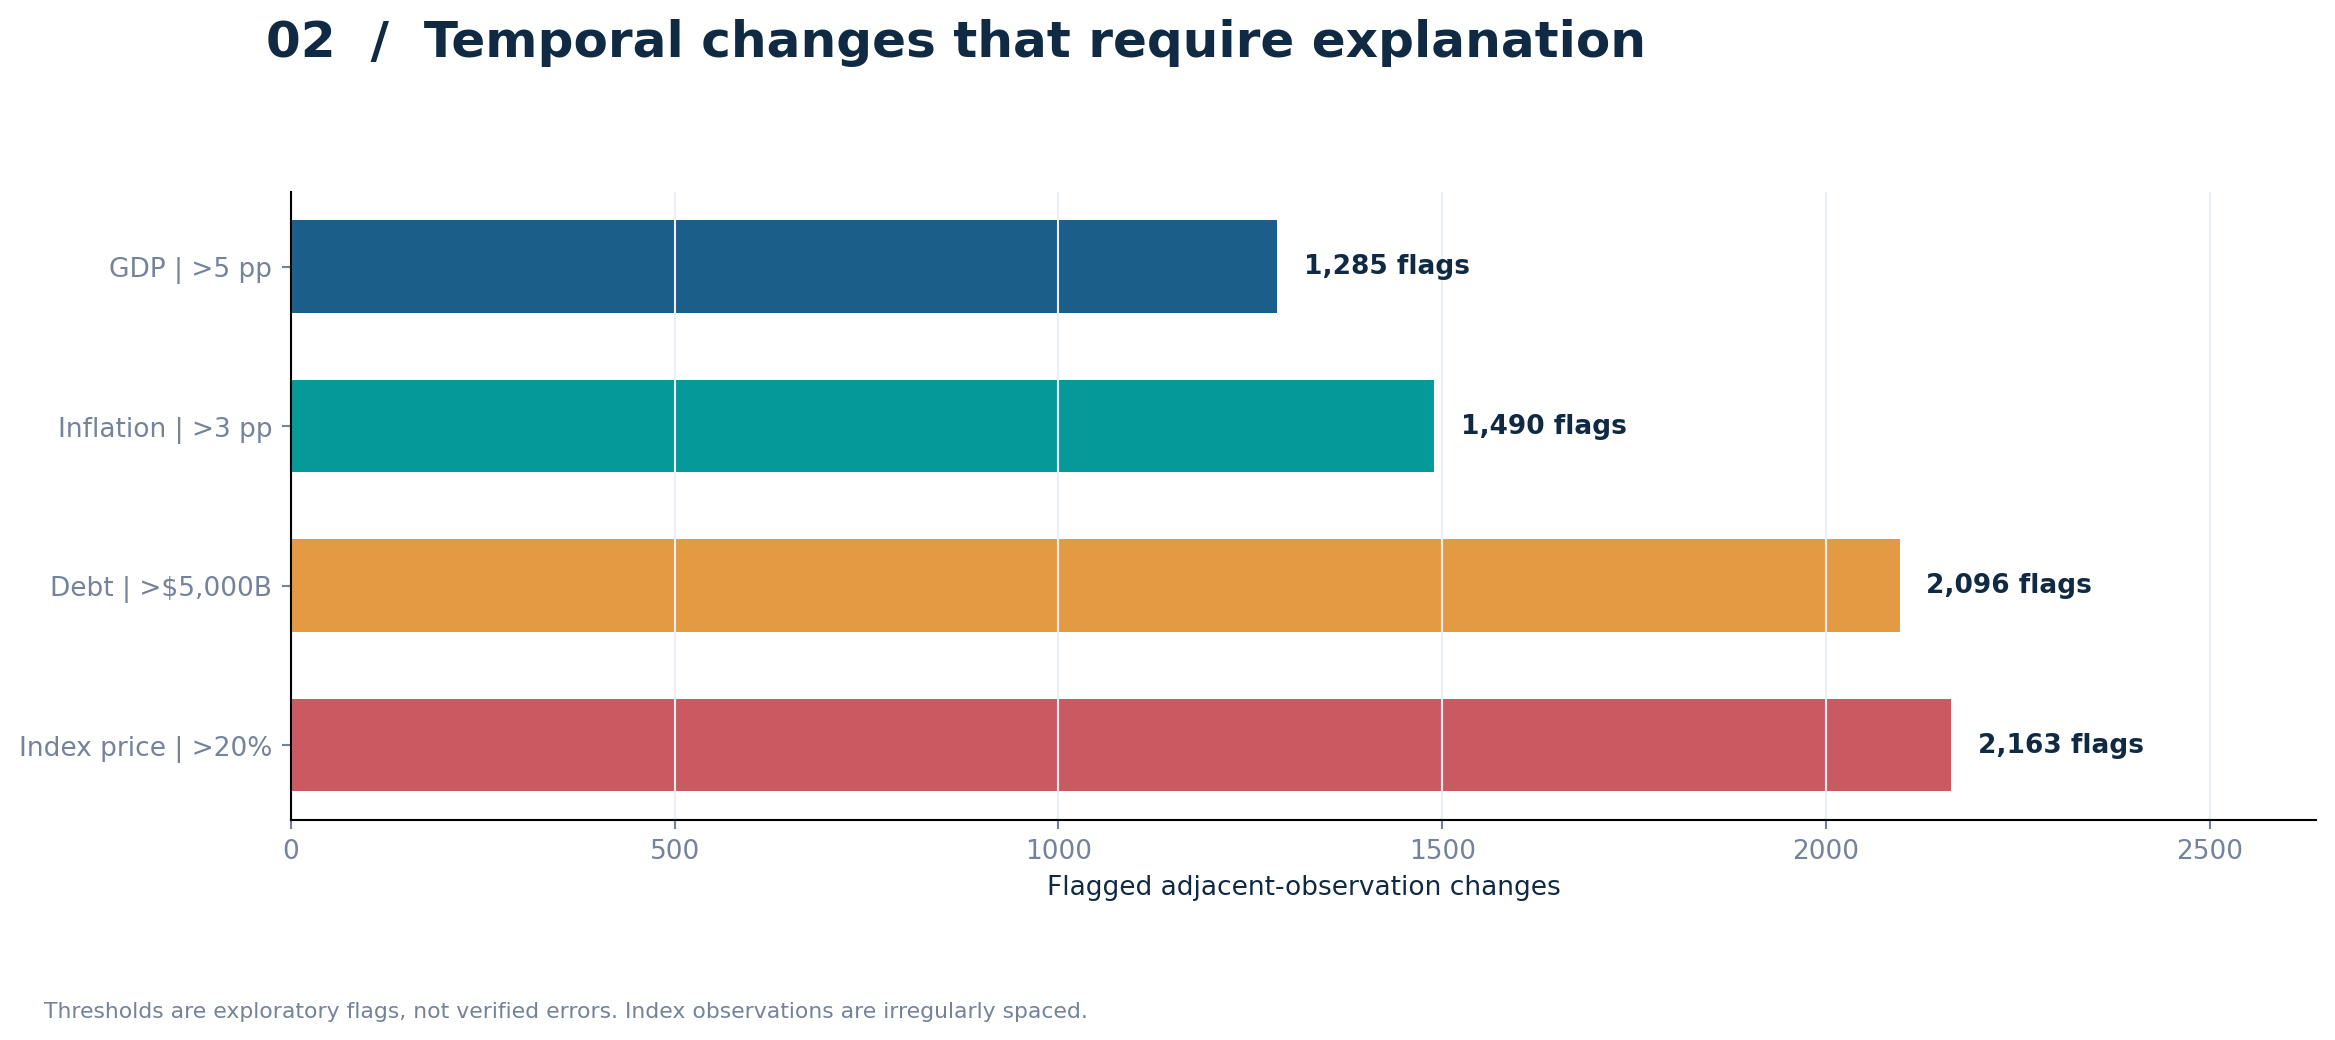

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "02_temporal_jump_flags.png")))

# 4. EDA: trends, distributions, seasonality and relationships

**Visualization design:** Each variable is given its own axis; visually unrelated units are not drawn on the same vertical scale. Moving means clarify *descriptive patterns* but should not be interpreted as economic evidence without a trusted source.

We compare **Pearson (linear)** with **Spearman (rank monotonic)** correlations; show levels versus first differences; examine month-of-year distributions; and compute cross-correlations over ±12 months. These findings describe the supplied data and do not establish causality or predictive power.

In [ ]:
pearson=plot_eda(monthly)
display(pearson.round(3))
print('Inflation–interest correlation:',round(float(pearson.loc['Inflation Rate (%)','Interest Rate (%)']),3))

,GDP Growth (%),Inflation Rate (%),Unemployment Rate (%),Interest Rate (%)
GDP Growth (%),1.000,0.019,-0.013,0.012
Inflation Rate (%),0.019,1.000,-0.020,0.063
Unemployment Rate (%),-0.013,-0.020,1.000,0.061
Interest Rate (%),0.012,0.063,0.061,1.000


Inflation–interest correlation: 0.063


**Figure: Monthly descriptive indicator trends, four separate panels**

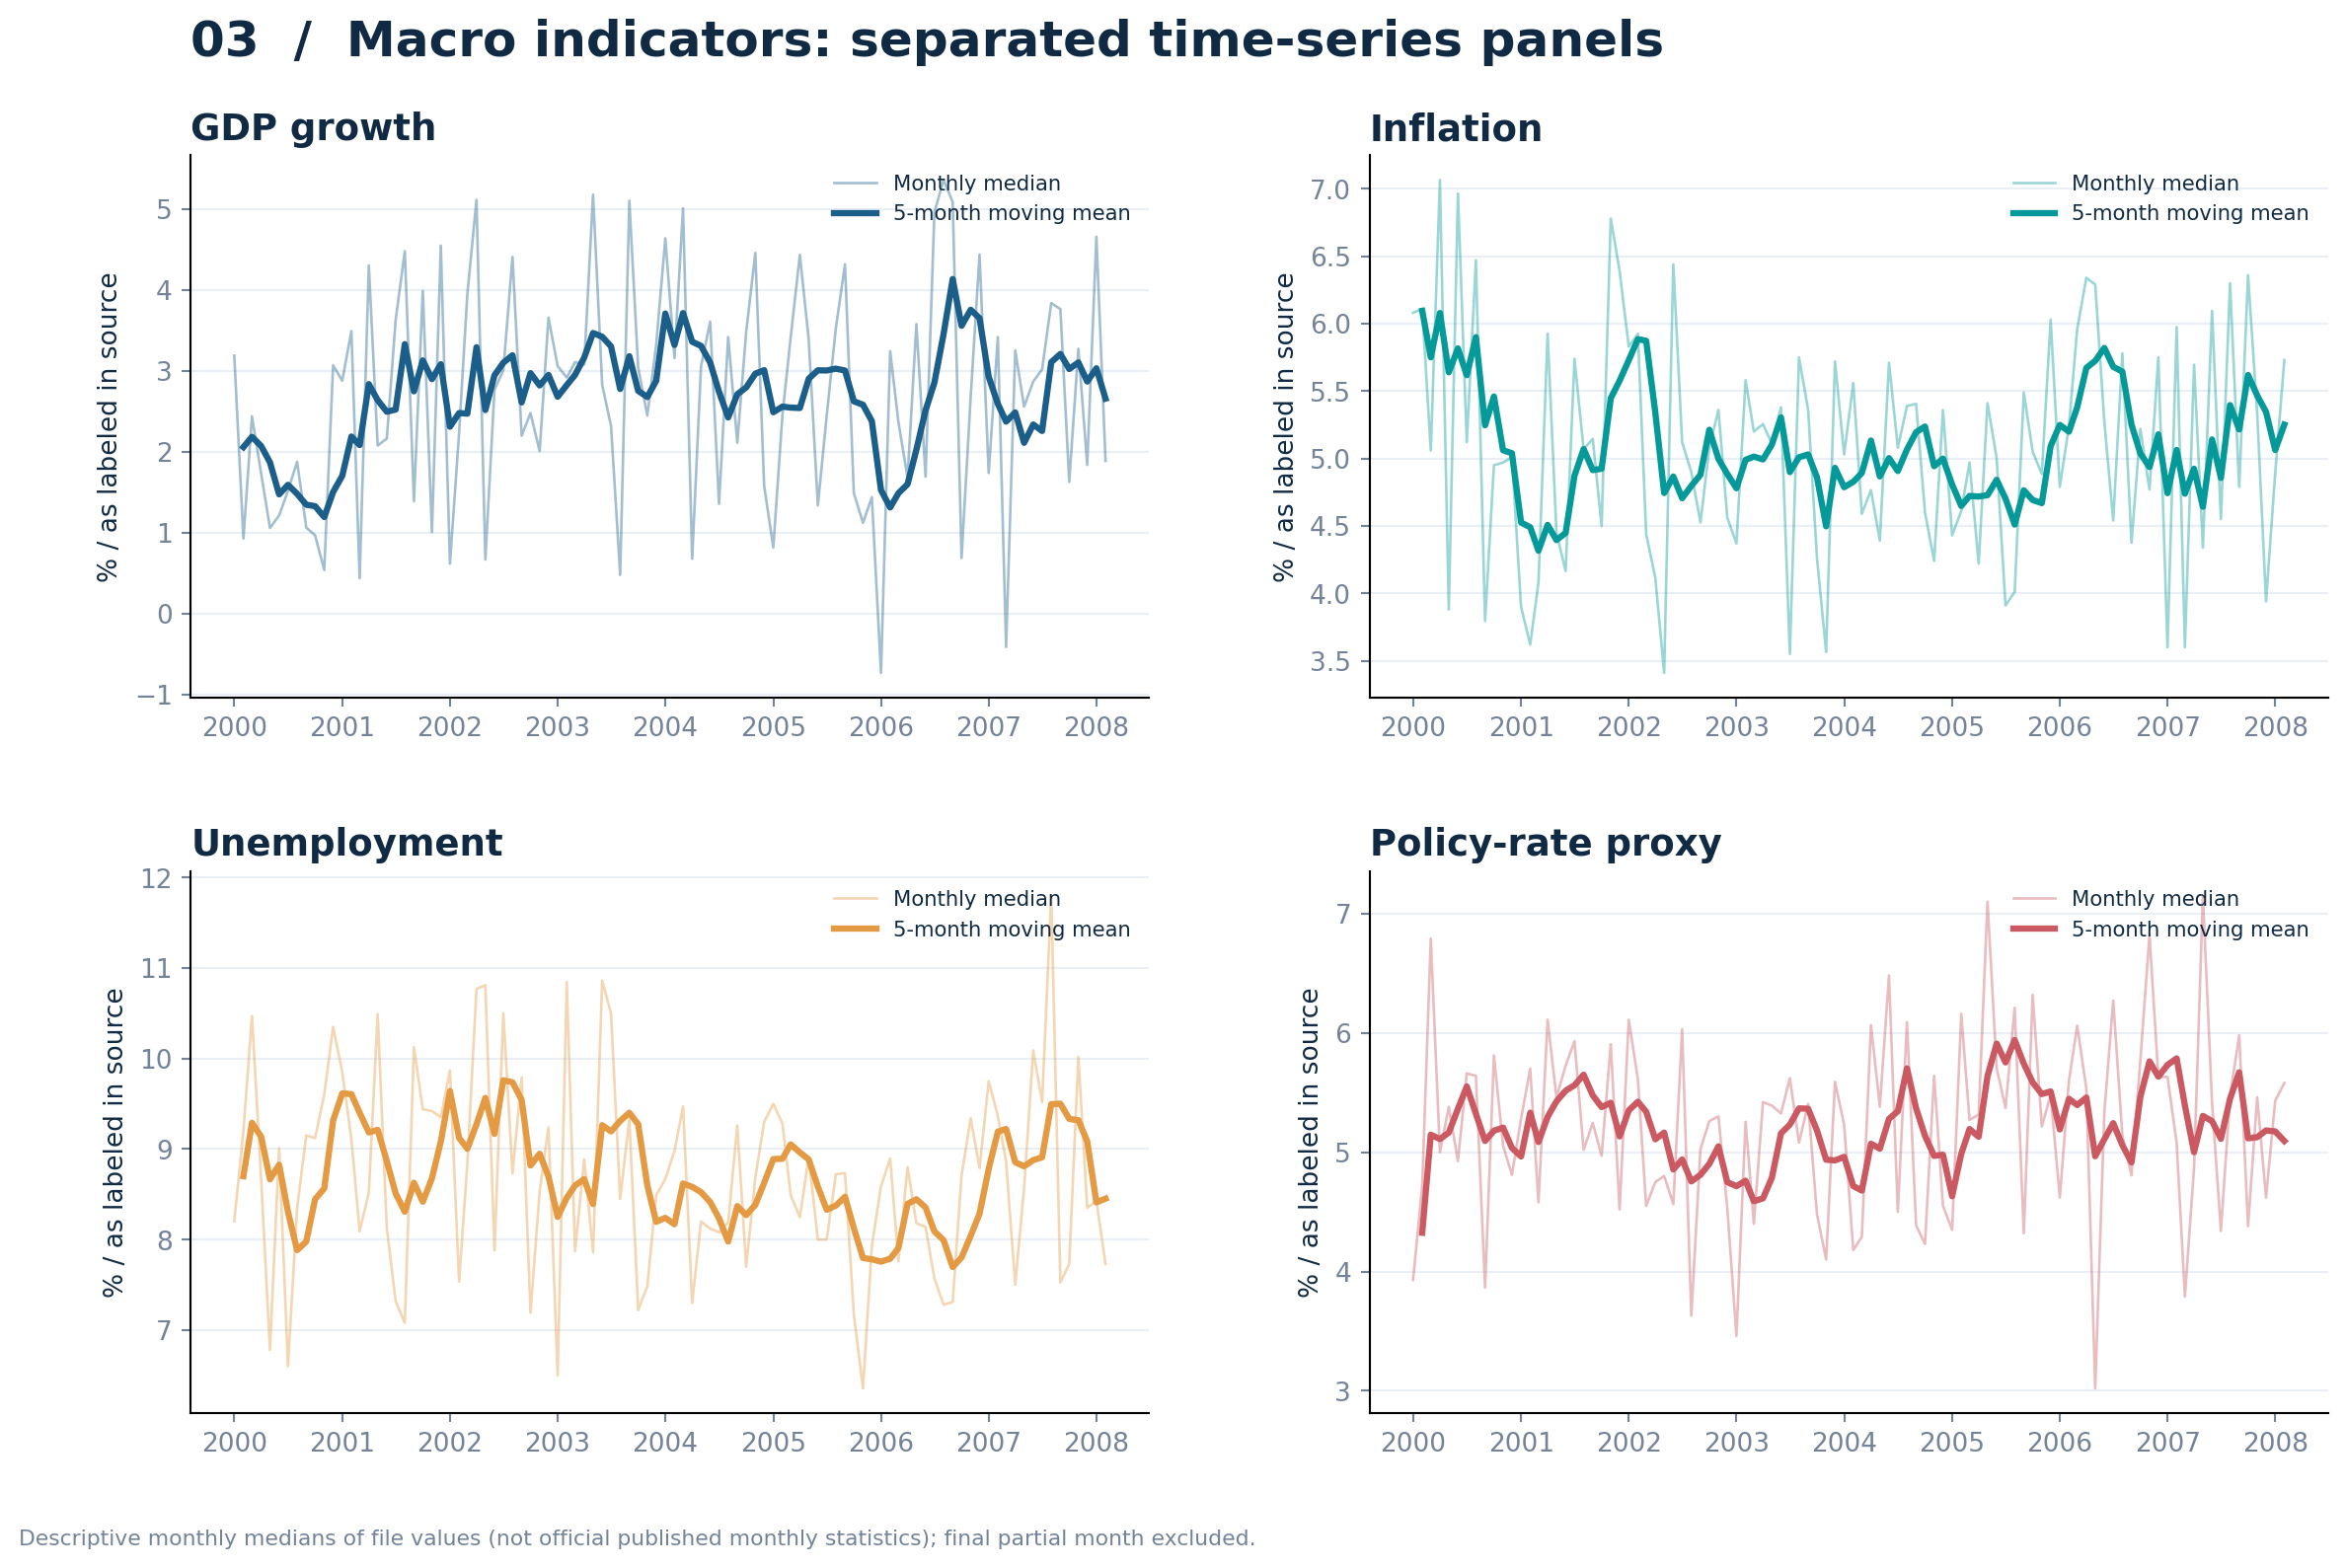

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "03_macro_trends.png")))

**Figure: Raw daily macroeconomic distributions**

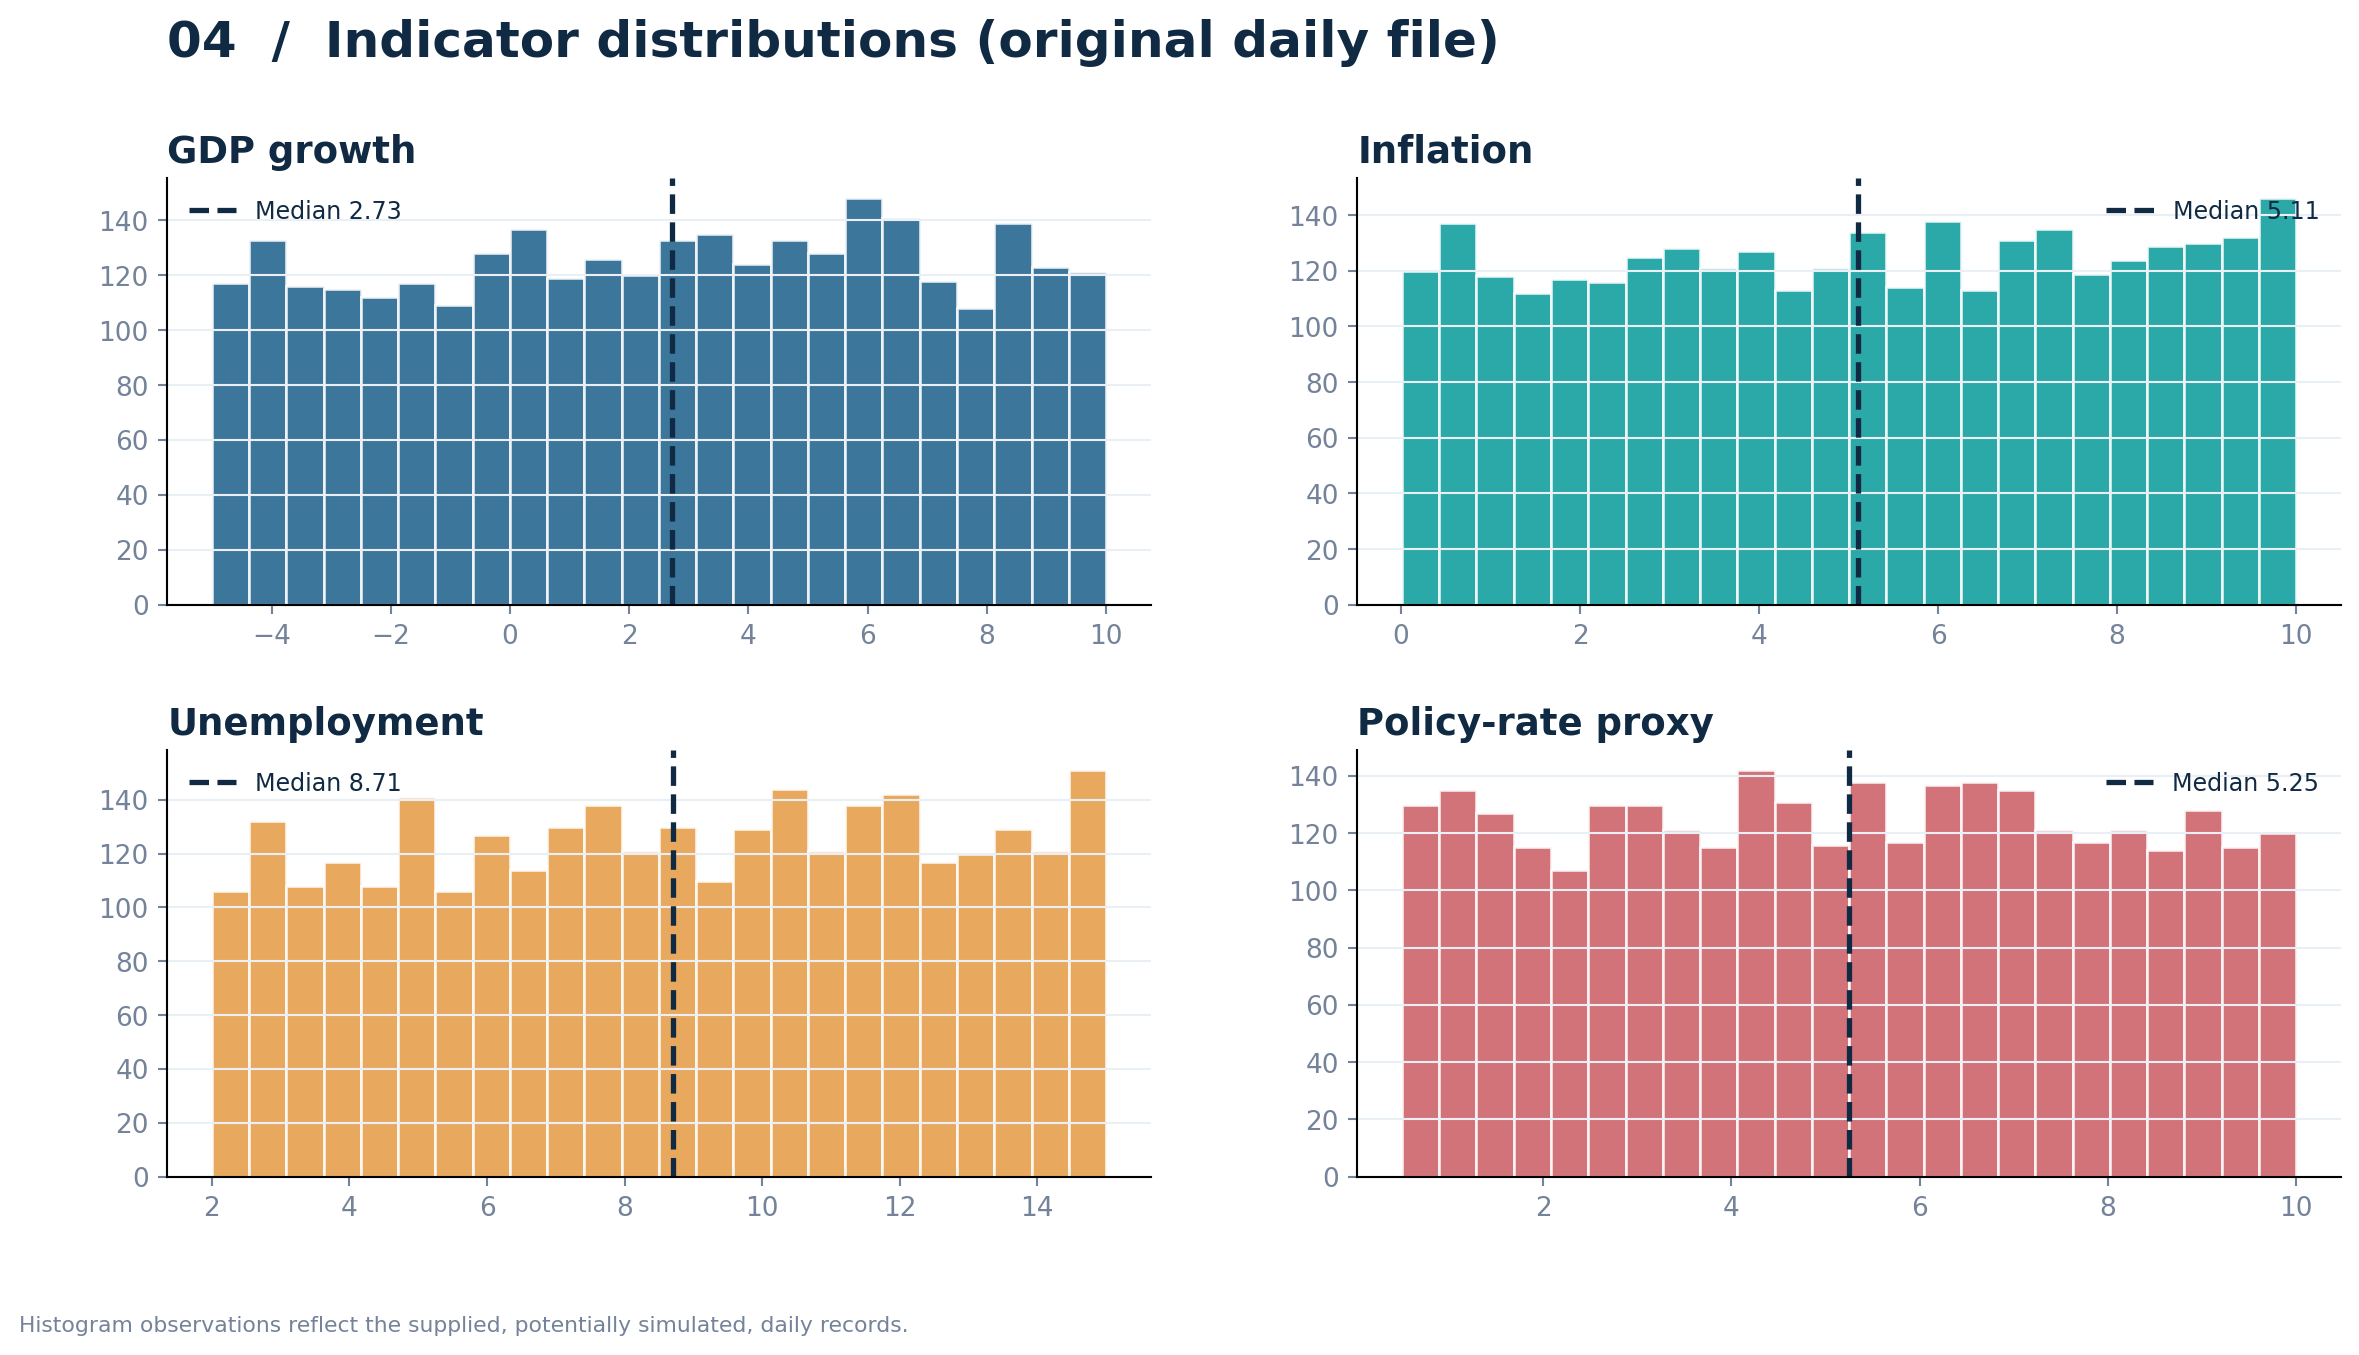

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "04_macro_distributions.png")))

**Figure: Index-labeled price histories in separate panels**

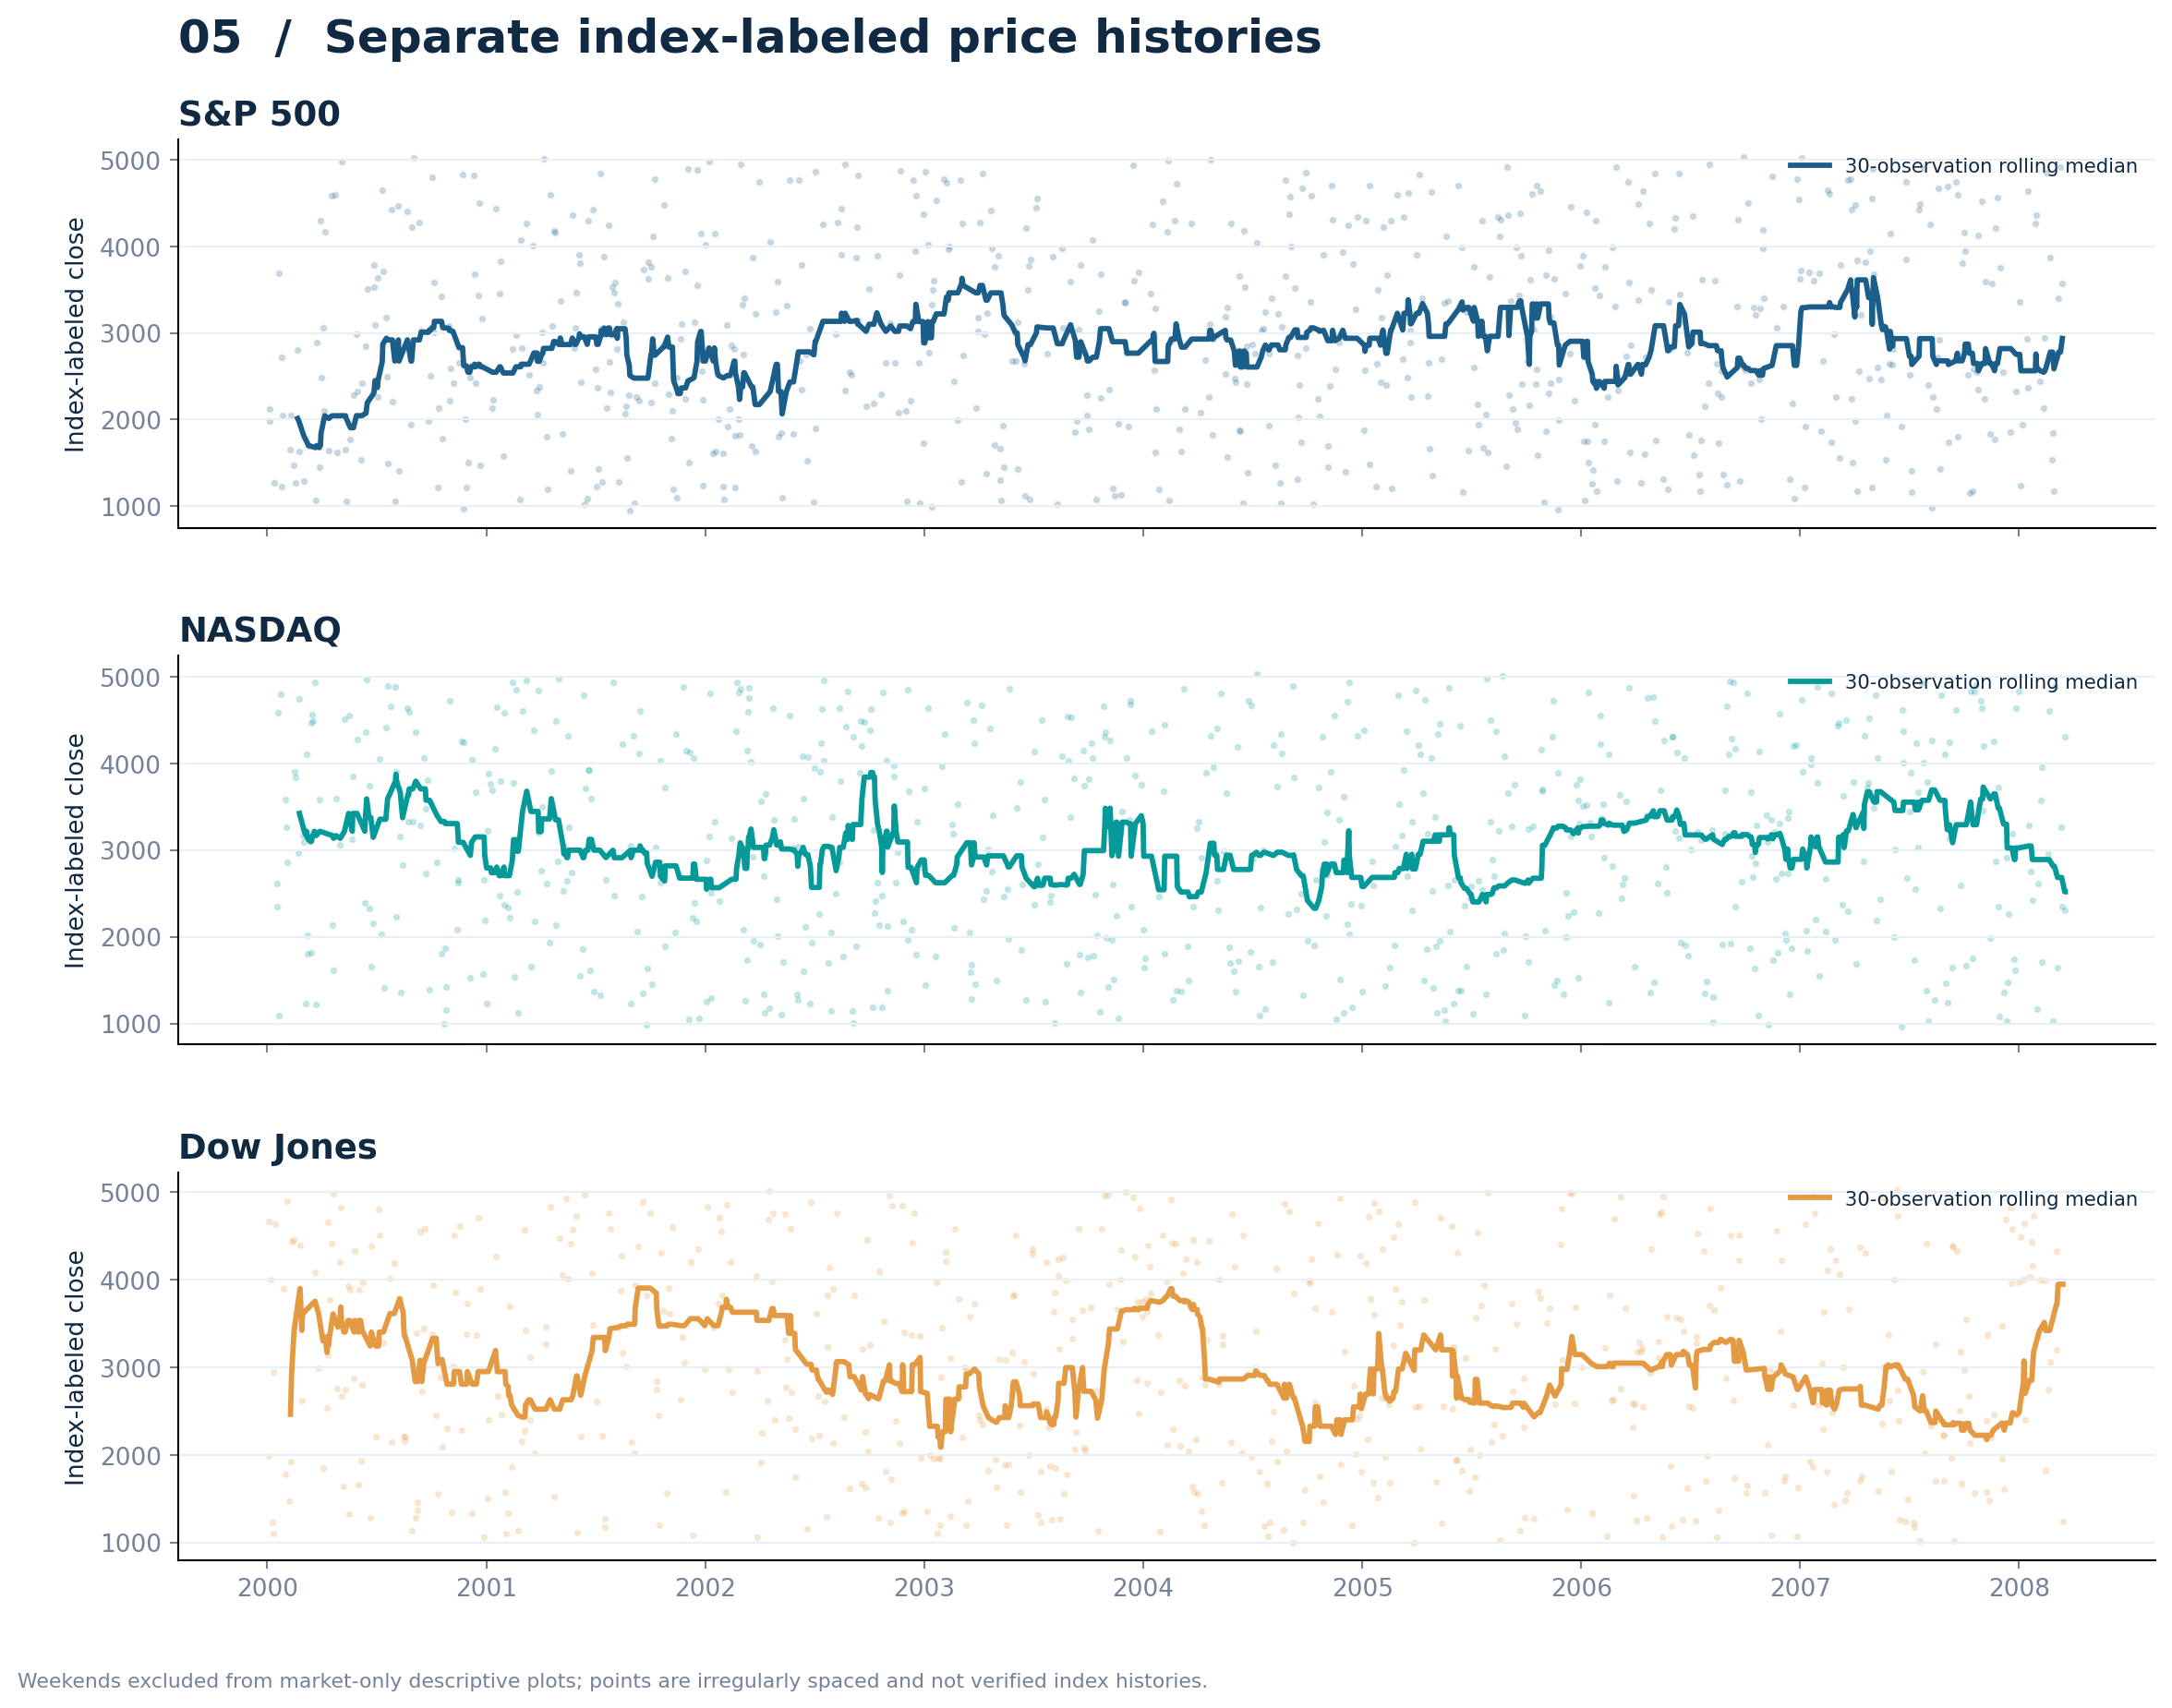

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "05_index_trends_by_index.png")))

**Figure: Pearson versus Spearman correlation matrix**

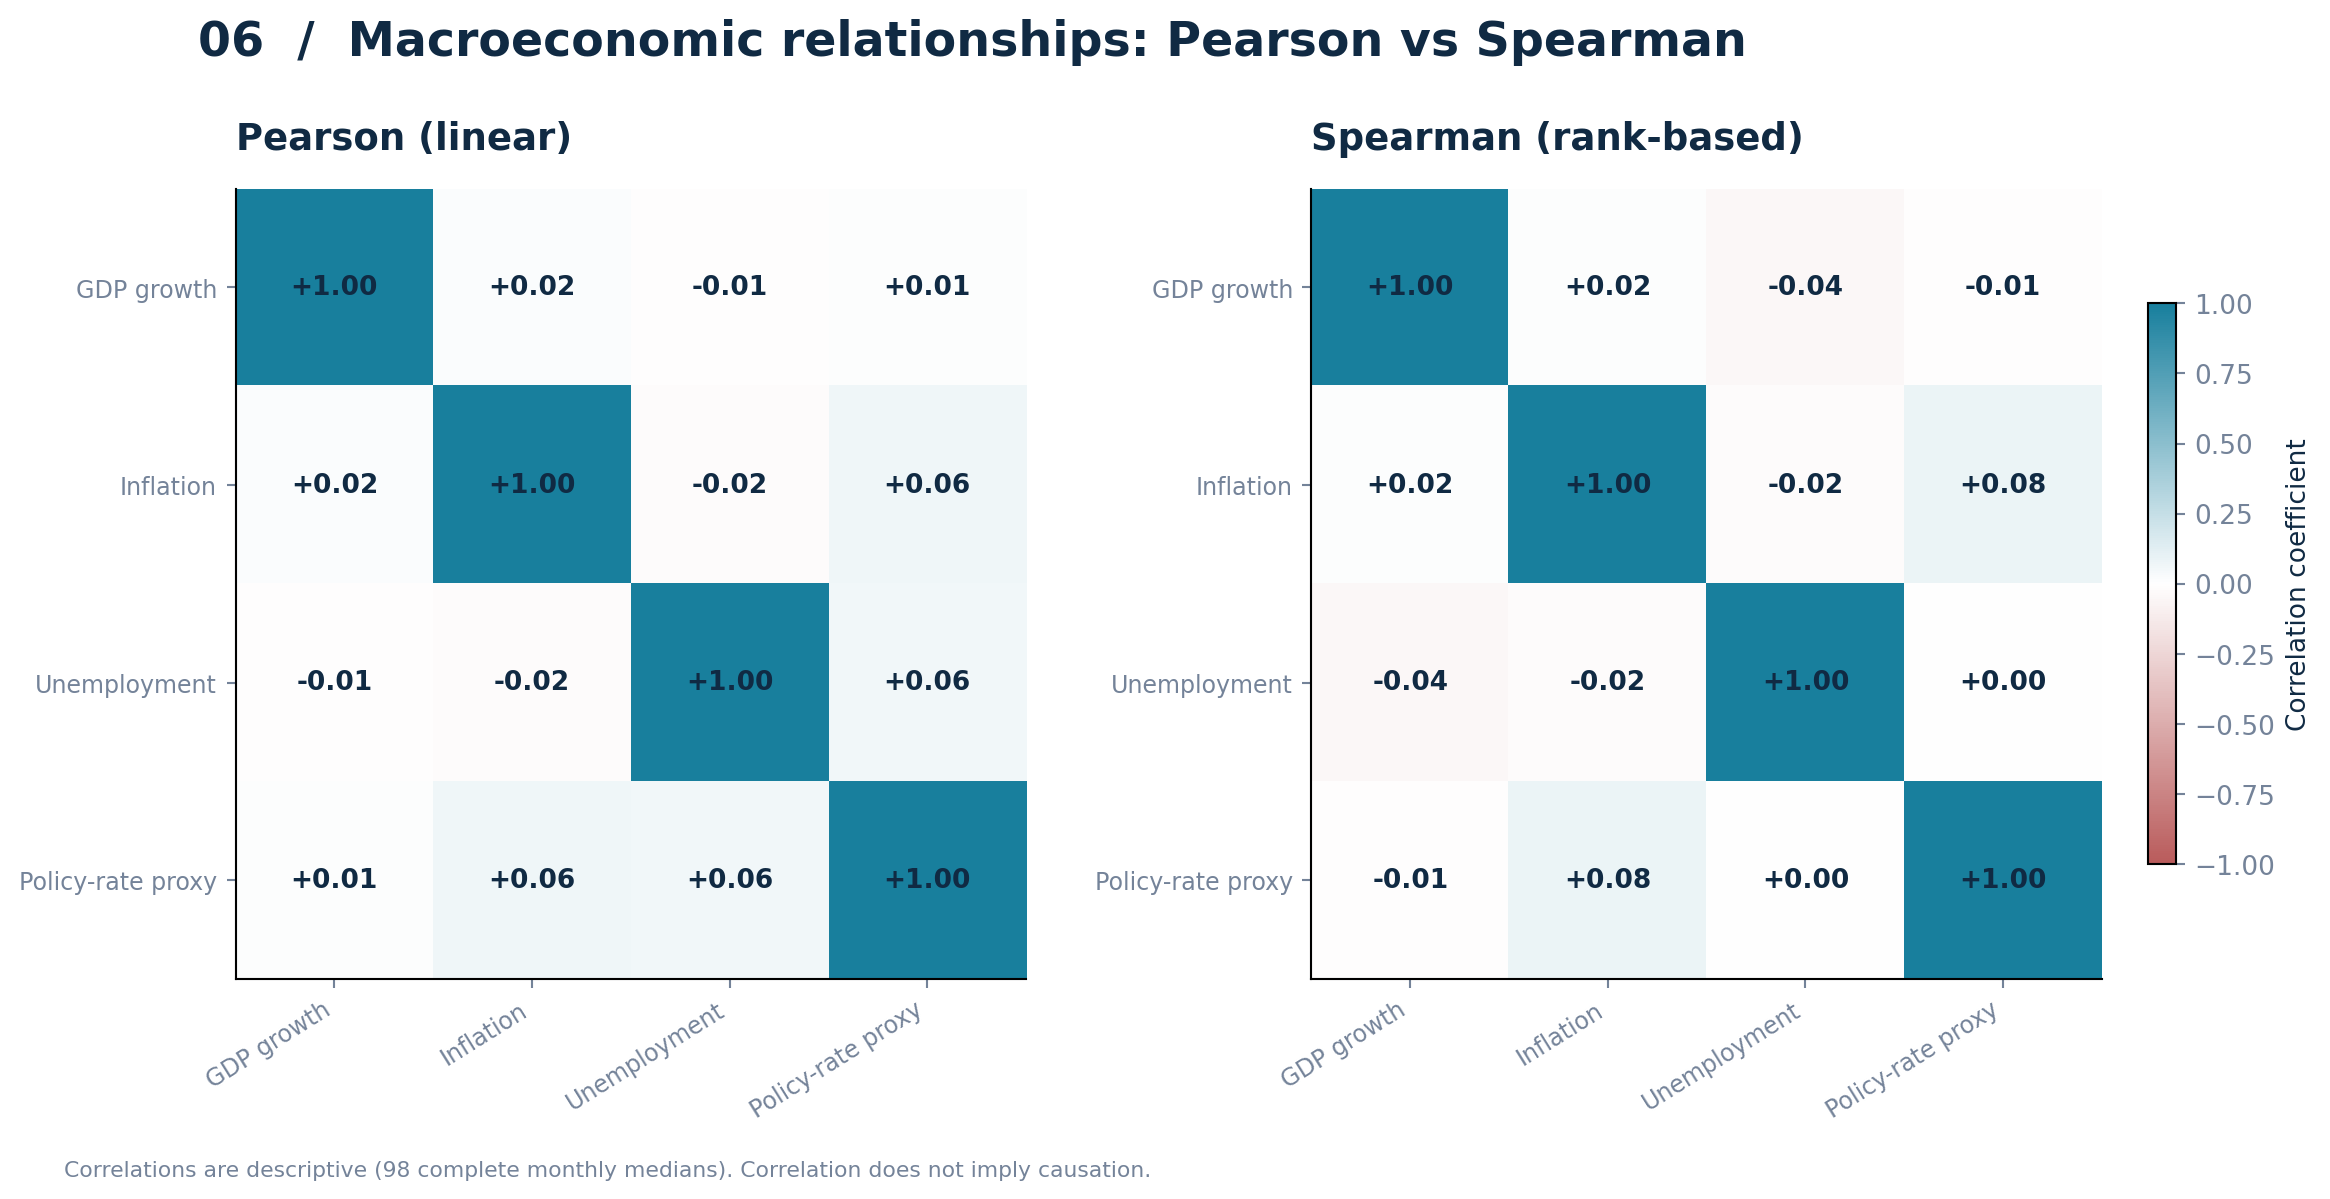

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "06_macro_correlations.png")))

**Figure: Correlation after differencing**

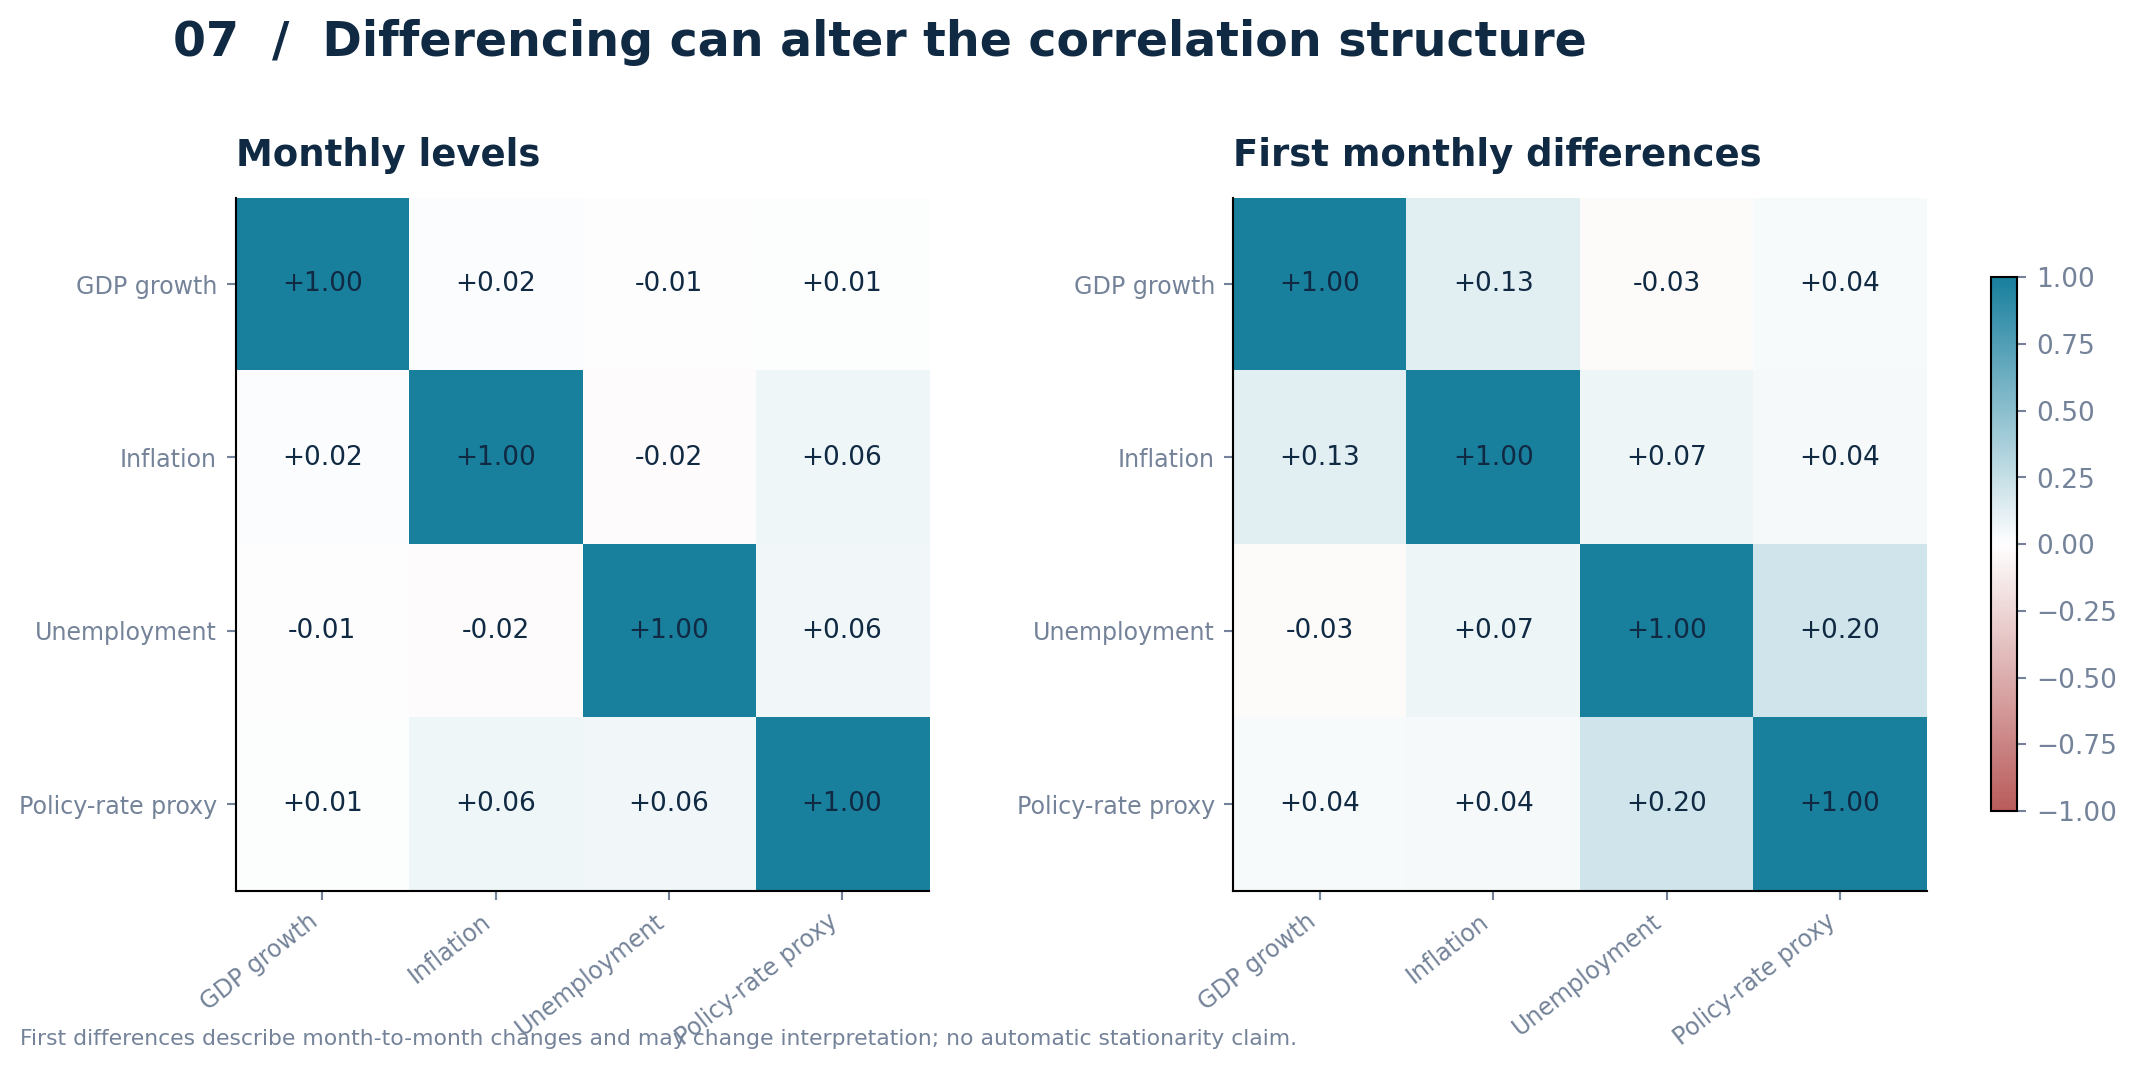

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "07_levels_vs_differences.png")))

**Figure: Seasonality: inflation and unemployment monthly boxplots**

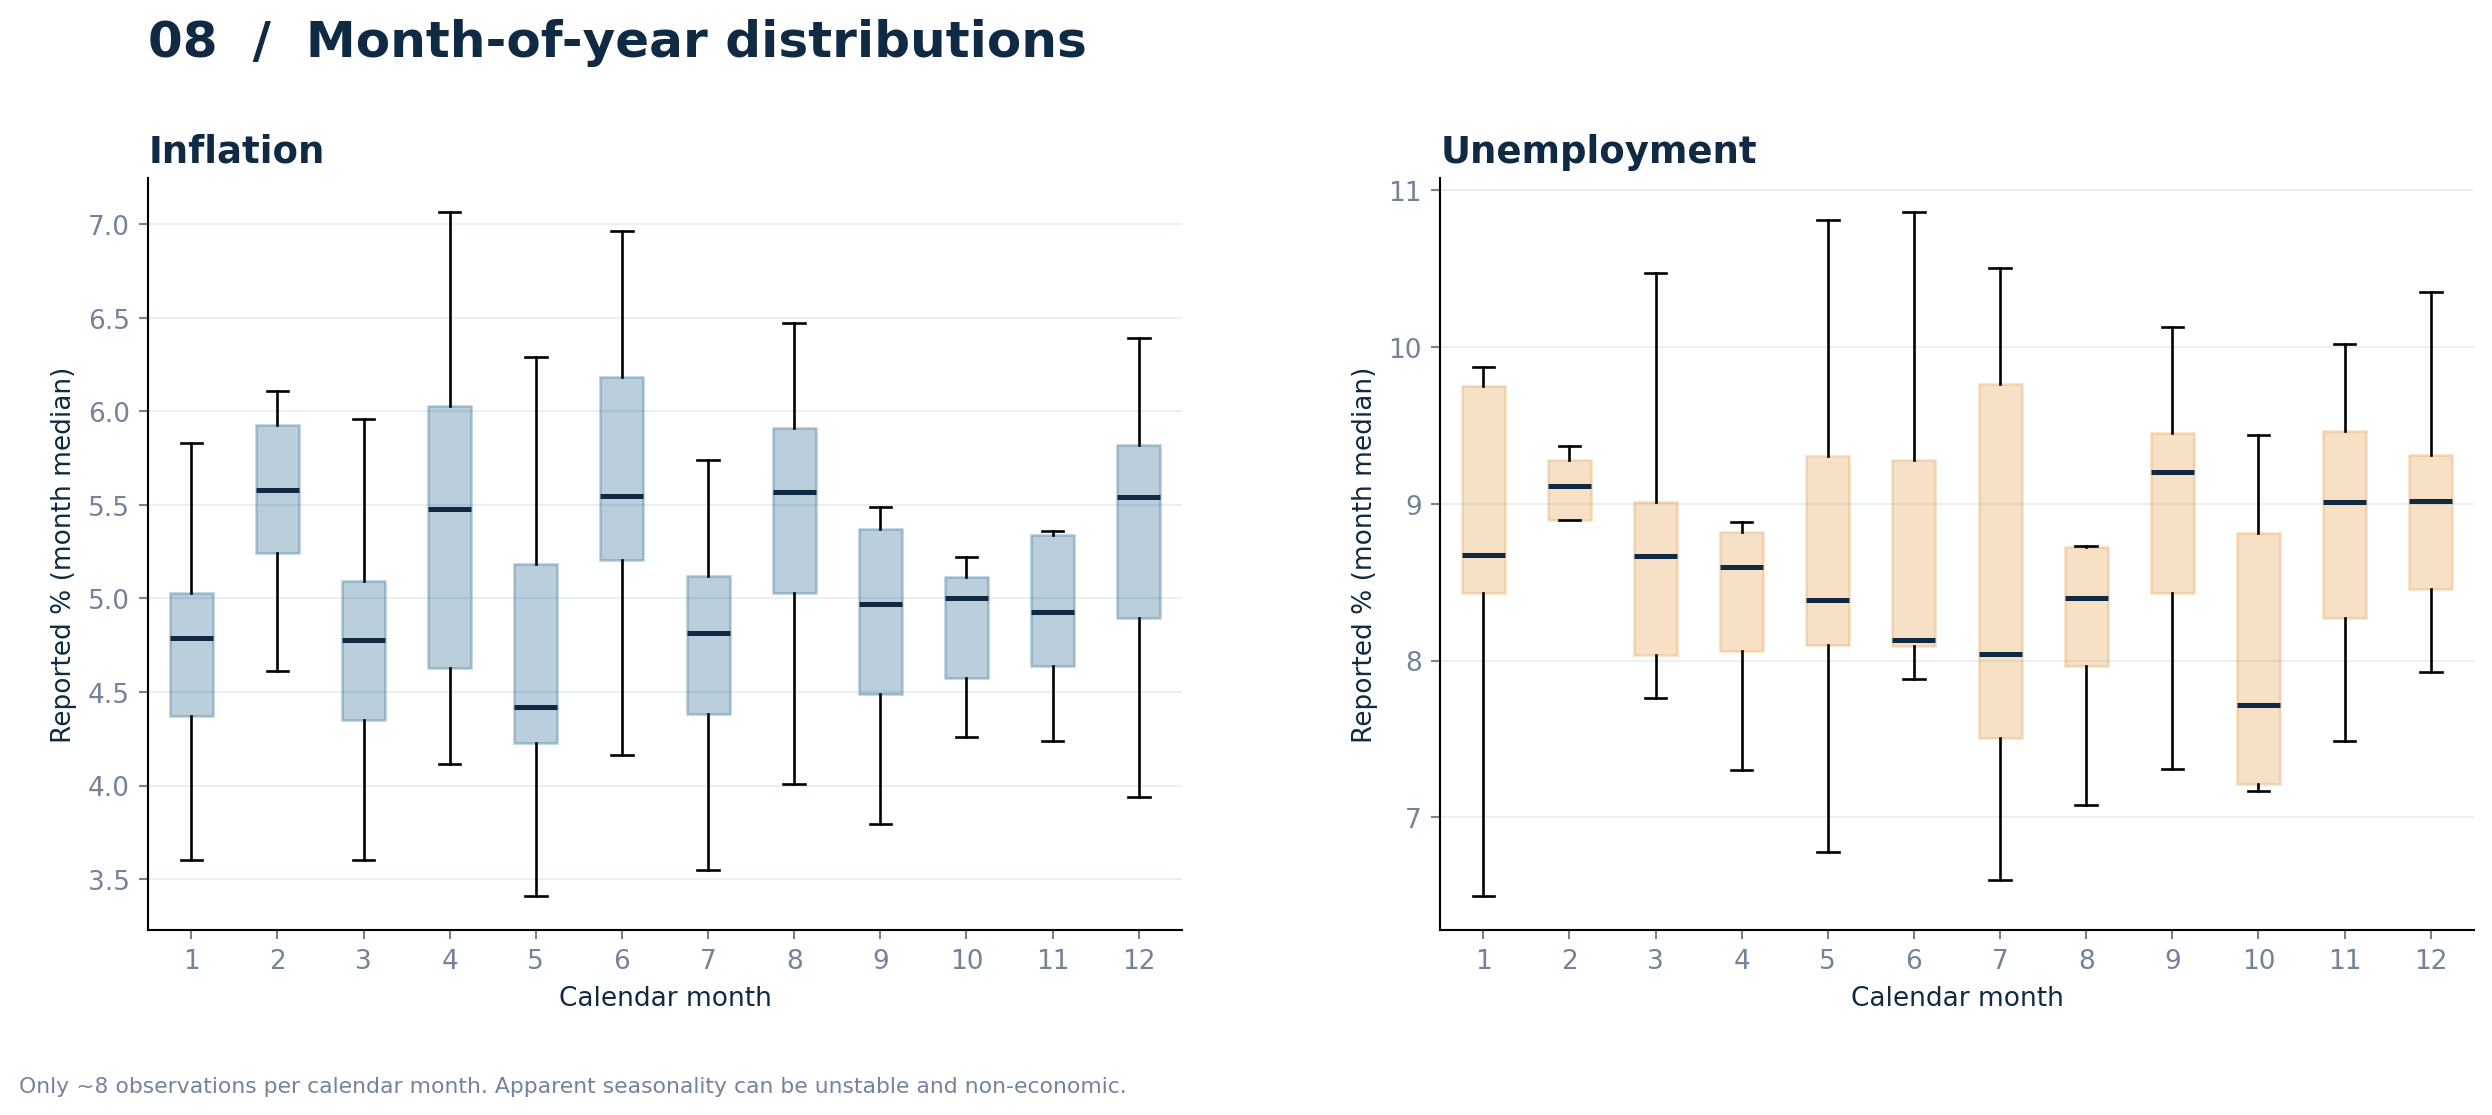

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "08_month_of_year_seasonality.png")))

**Figure: Lagged associations over ±12 months**

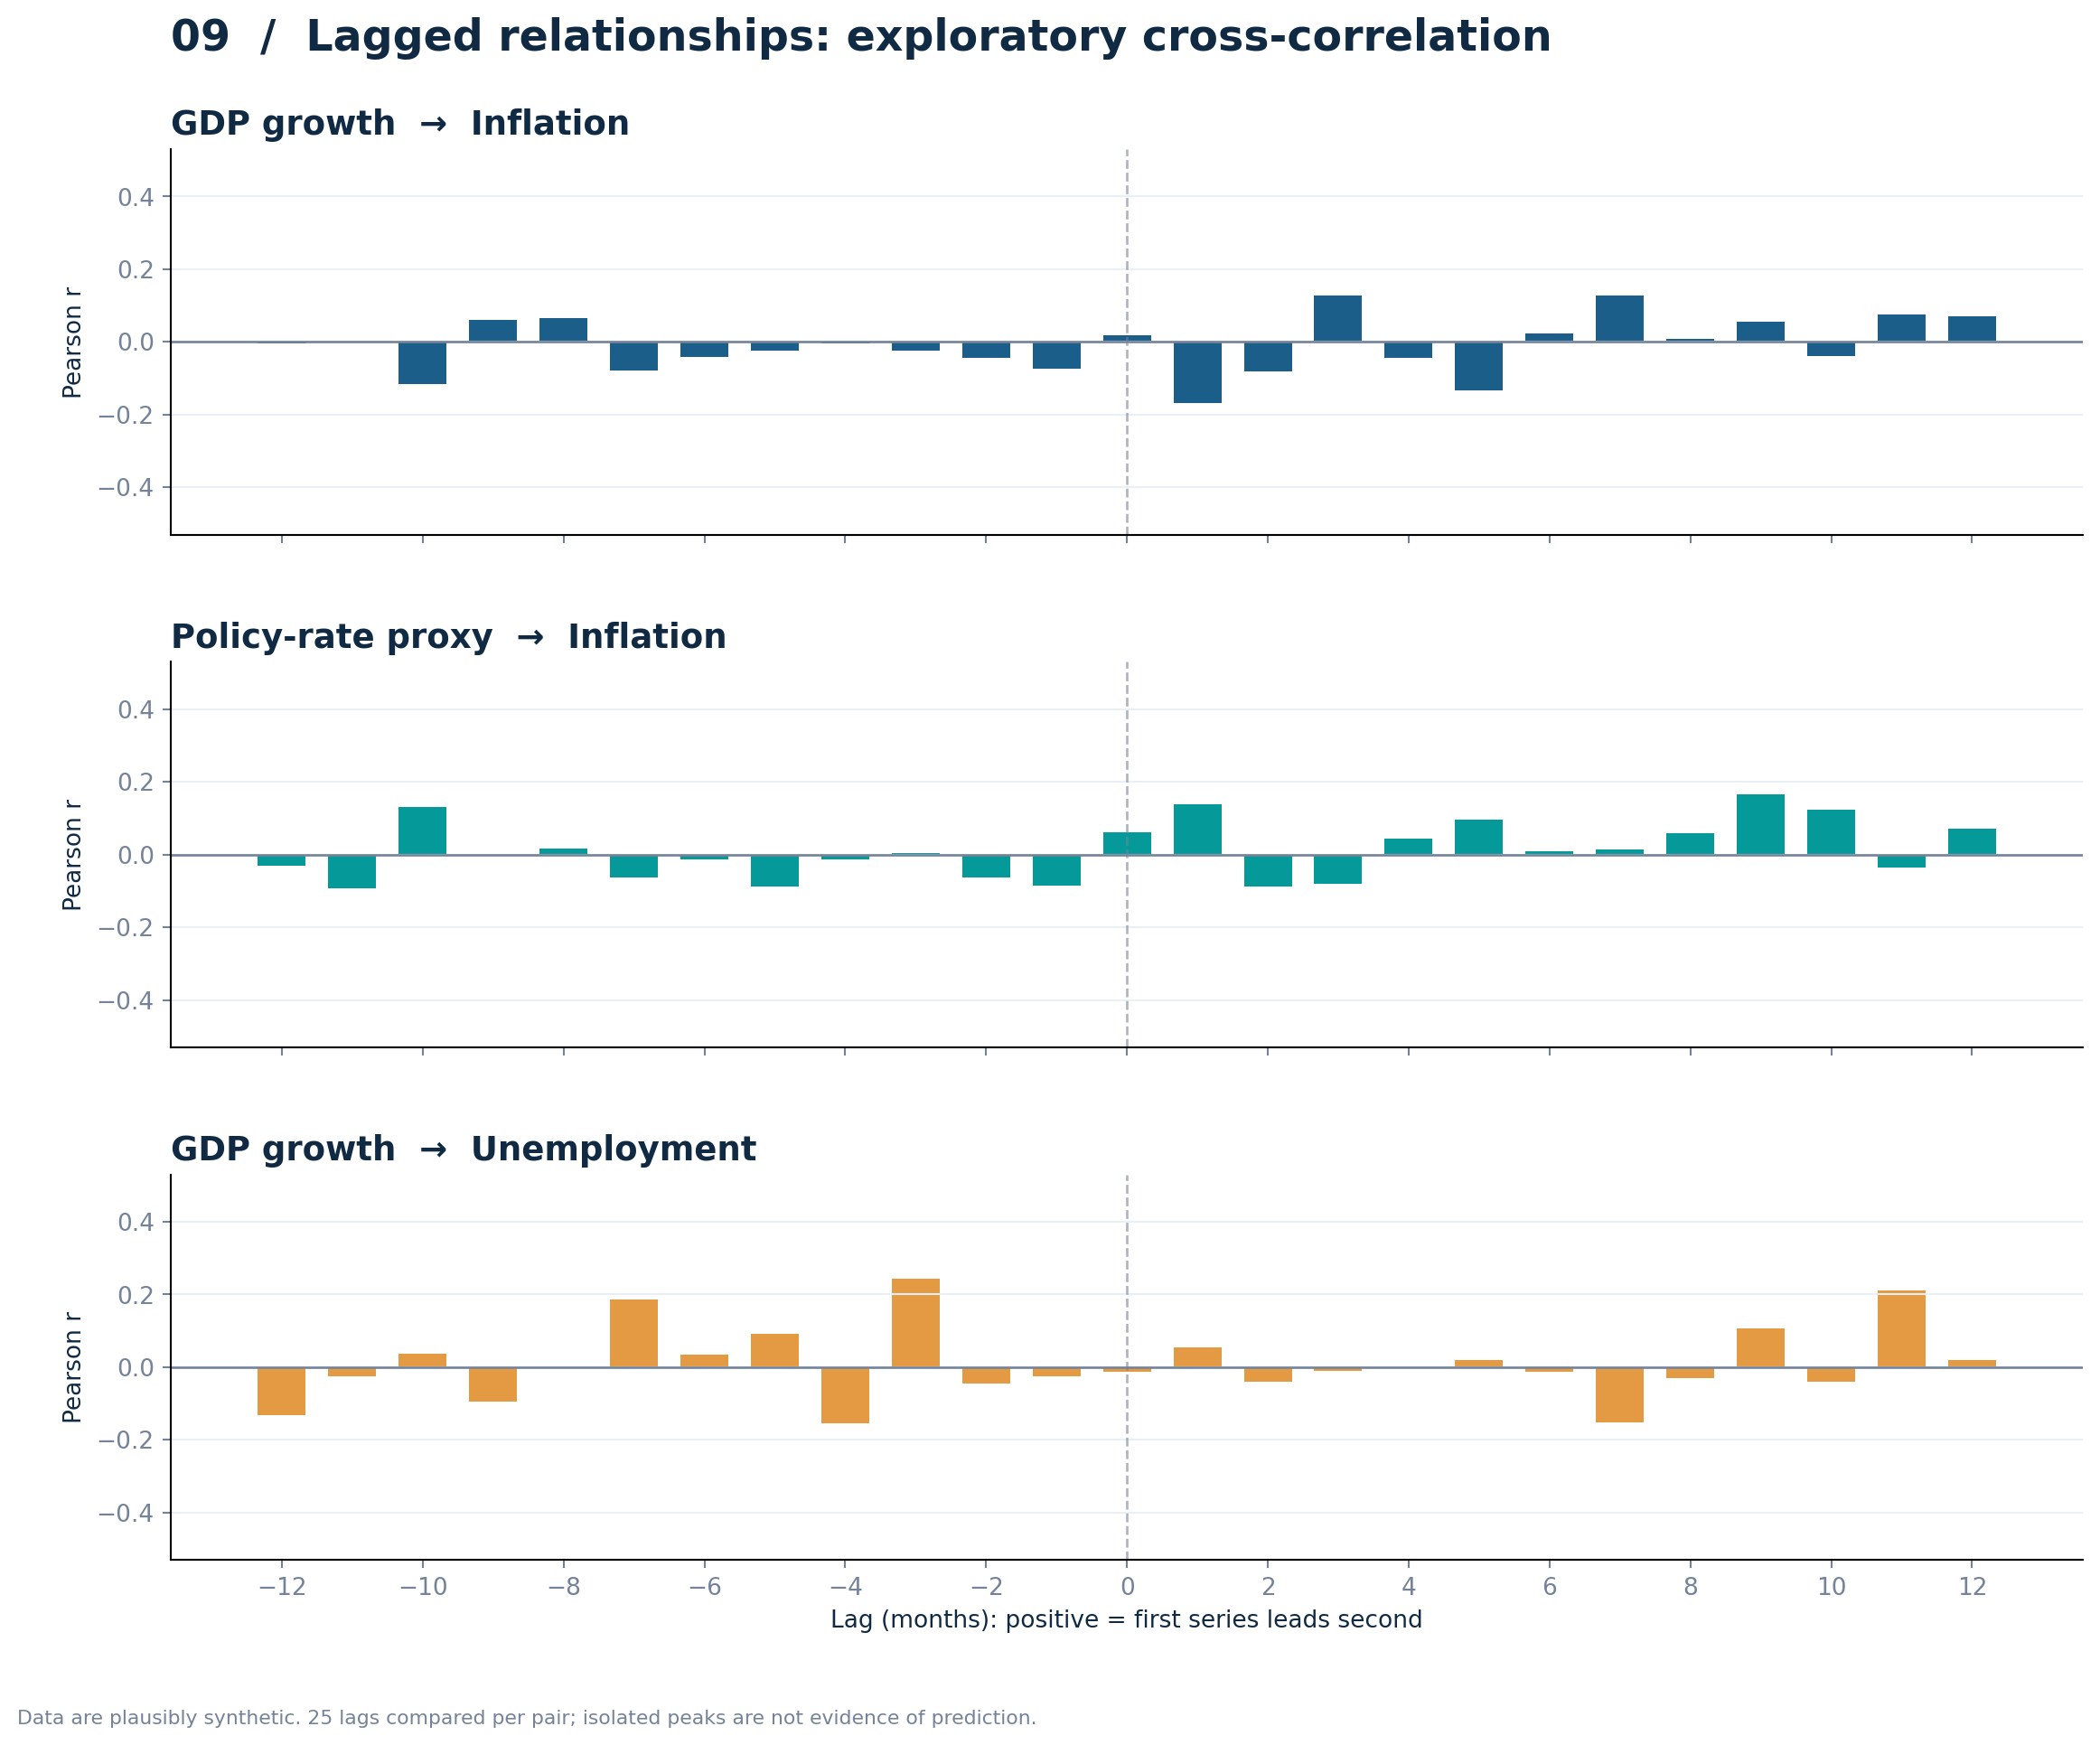

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "09_cross_correlations.png")))

### EDA findings
The correlation matrix shows mostly **weak contemporaneous linear relationships**. For example, the Pearson coefficient for inflation versus interest rate is about **+0.063** (98 monthly medians). Strong-looking isolated lead–lag peaks are not conclusive because many lags are examined.

**Caution:** A nonsignificant or small coefficient in this suspect dataset does **not** imply that real inflation, employment and monetary policy are economically unrelated.

# 5. Feature engineering
The key forecasting rule is that a prediction for month *t* may use features **known at the end of month t–1**, but not values from month *t*.

Constructed features include:
- Prior 1/2/3-month values for GDP, inflation, unemployment and rates.
- Historical-only 3-month moving averages and inflation volatility.
- Lagged **real-interest spread** (interest minus inflation) and lagged inflation change.
- Prior-month gold and oil returns; known calendar sine/cosine features.
- Separately: per-index returns, log returns, rolling means and rolling volatilities between *actual observed* index rows (irregular spacing noted).

In [ ]:
features=engineer_features(monthly)
print('Number of predictor columns:',features.shape[1]);print('First fully populated month:',features.dropna().index.min().date())
display(features.dropna().head(3).round(3).T)
plot_features(monthly,features)

Number of predictor columns: 23
First fully populated month: 2000-04-01


Date,2000-04-01,2000-05-01,2000-06-01
gdp_growth_lag_1,2.440,1.735,1.060
gdp_growth_lag_2,0.930,2.440,1.735
gdp_growth_lag_3,3.190,0.930,2.440
gdp_growth_prior_3m_mean,2.187,1.702,1.745
inflation_lag_1,5.060,7.065,3.880
inflation_lag_2,6.110,5.060,7.065
inflation_lag_3,6.080,6.110,5.060
inflation_prior_3m_mean,5.750,6.078,5.335
unemployment_lag_1,10.470,8.675,6.780
unemployment_lag_2,9.200,10.470,8.675


**Figure: Leakage-aware lagged features**

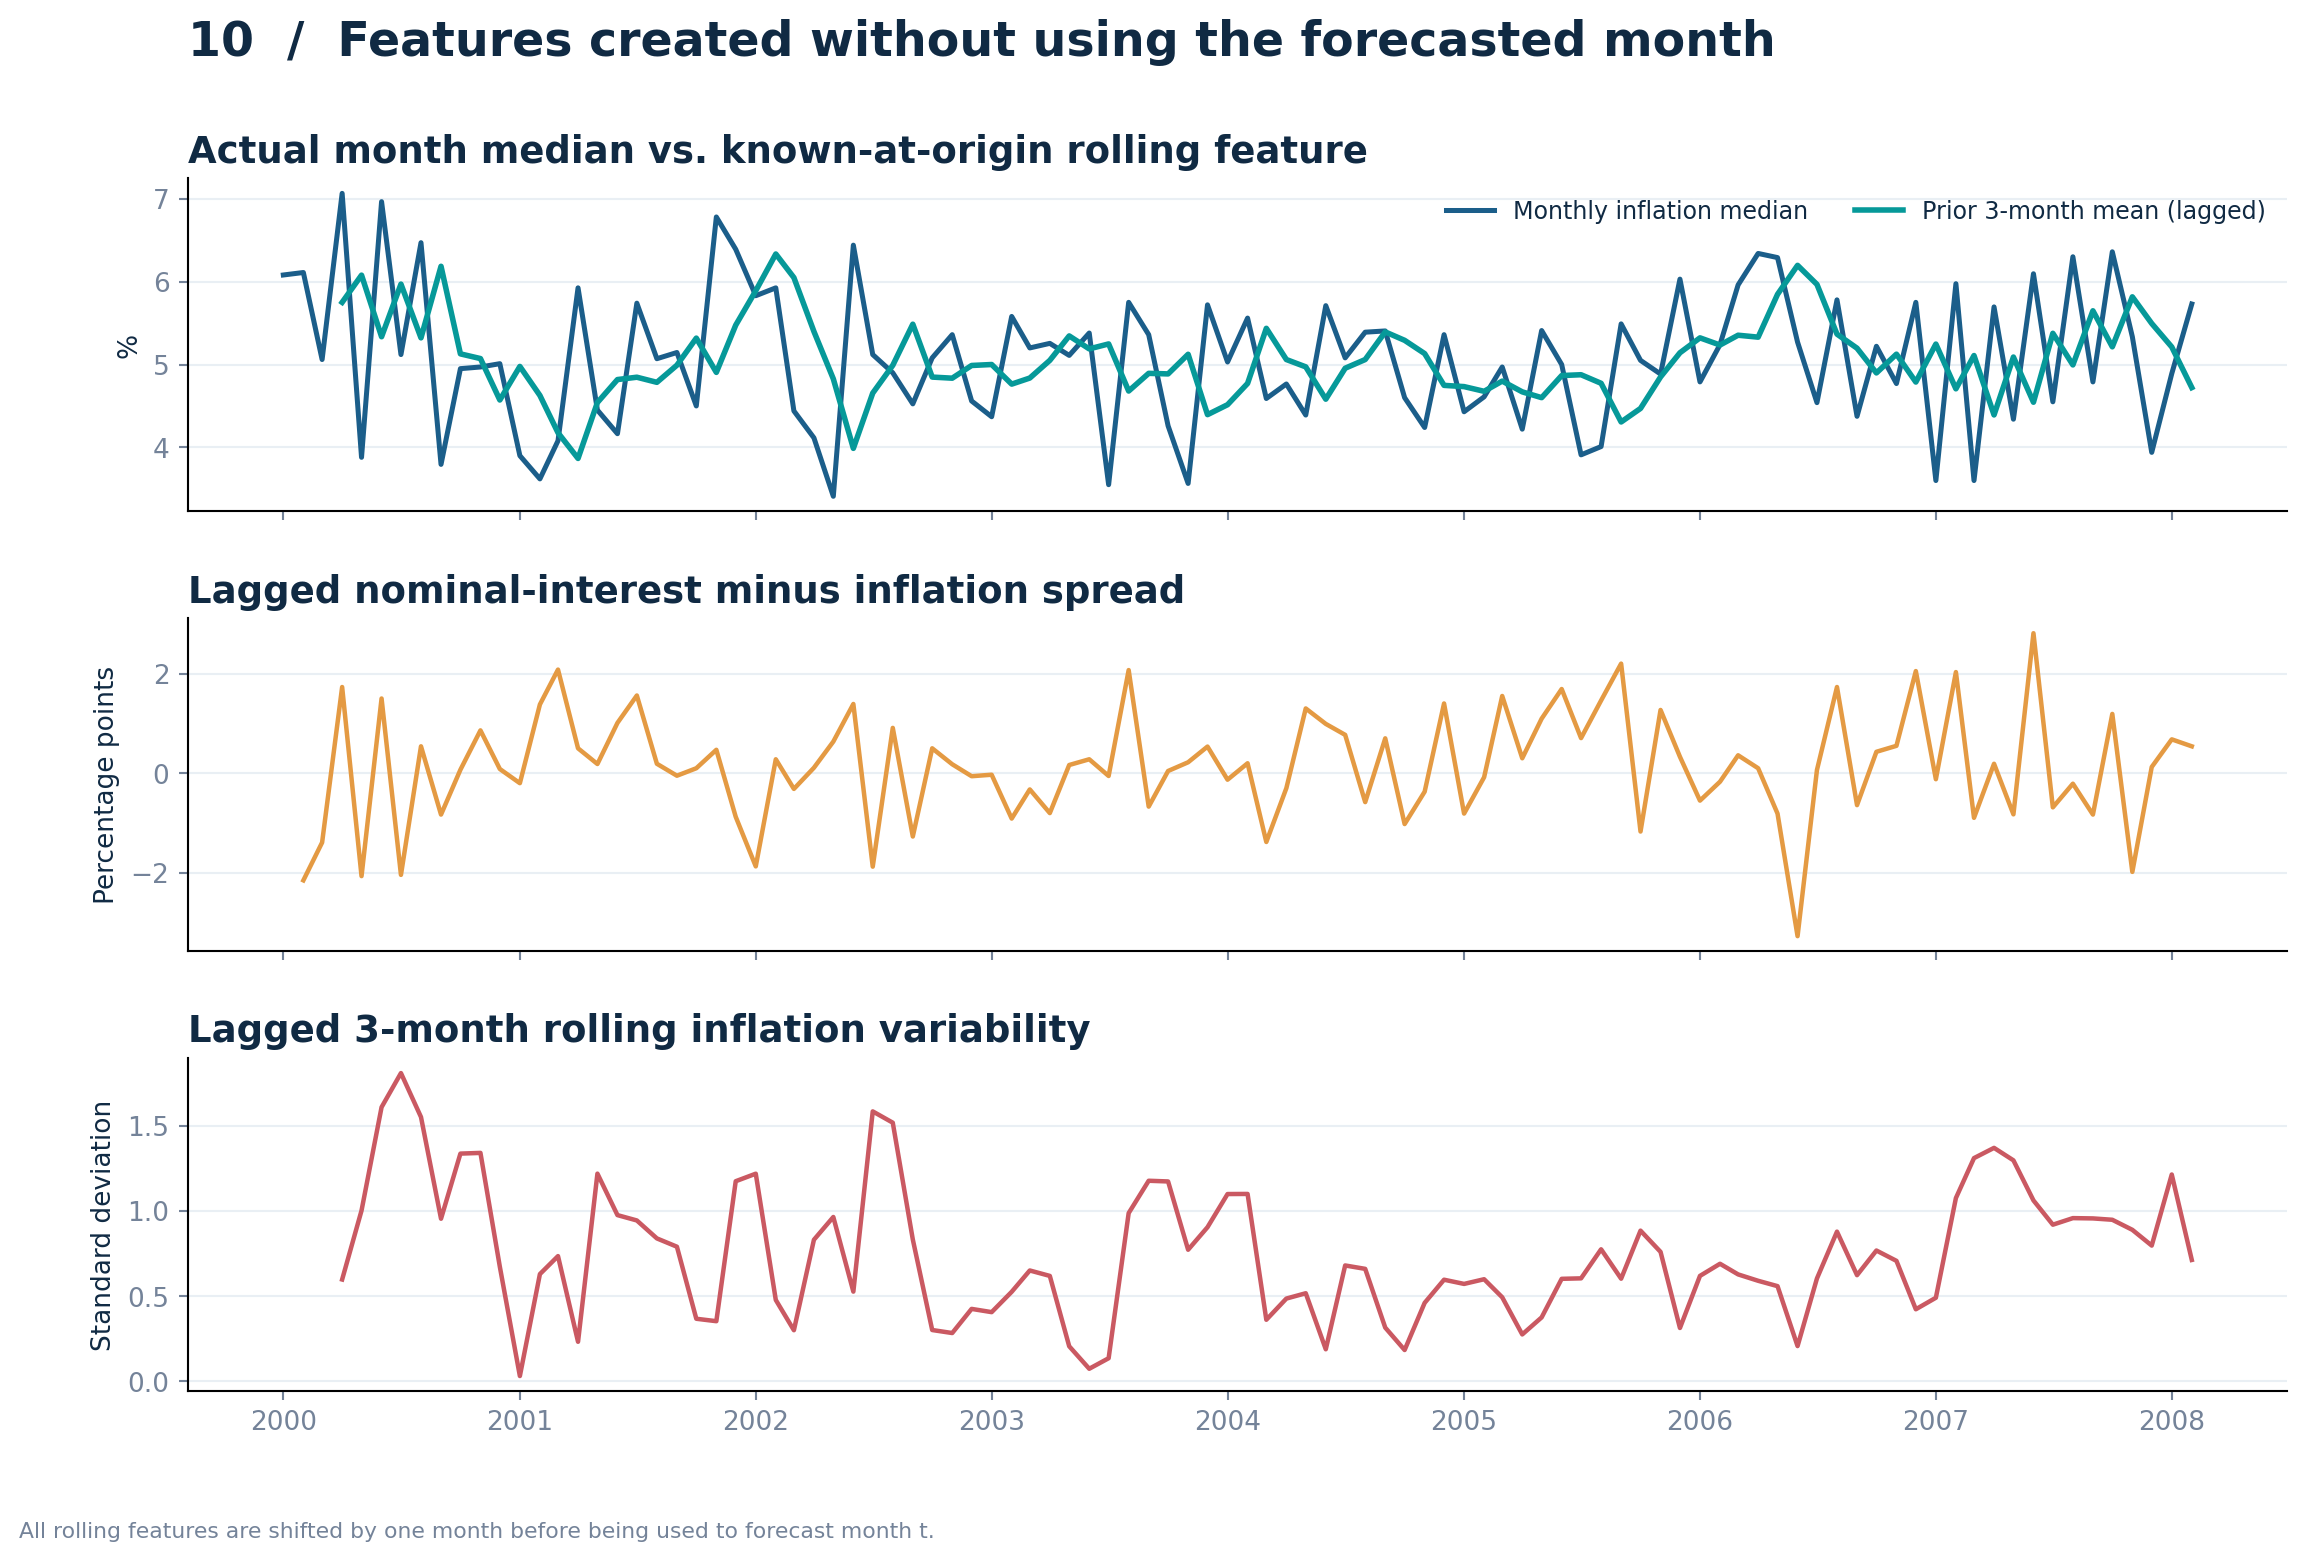

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "10_feature_engineering.png")))

# 6. Forecasting design and model training

**Targets:** inflation and unemployment (month descriptive medians). We forecast **one complete month ahead** using realized historical information only. A new observation is revealed before the next one-step-ahead prediction, which makes this an observed-history *rolling evaluation*, **not** an 18-month-ahead open-loop forecast.

| Set | Date range | N months | Role |
|---|---|---:|---|
| Training | Jan 2000–Dec 2004 | 60 | Initial parameter learning |
| Validation | Jan 2005–Aug 2006 | 20 | VAR lag and NN stopping selection; interval calibration |
| Test | Sep 2006–Feb 2008 | 18 | Unseen final scoring |

**Eight approaches:** persistence; 12-month seasonal naive; expanding historical mean; Ridge; Random Forest; four-indicator VAR; sequence-based LSTM; sequence-based GRU.

VAR lag order is chosen on validation from lag 1–3. LSTM/GRU learn from **six previous monthly multivariate observations**, use early stopping on validation and are retrained on the full development window at the selected number of epochs. All scalers are fitted only on permitted prior samples. These small neural models are included to satisfy the advanced-model comparison, **not because 98 months is enough for robust deep-learning economics**.

In [ ]:
metrics,predictions,protocol,actuals,test_indices=model_forecasts(monthly,features)
print('VAR selected lag:',protocol['VAR_selected_lag'])
print('LSTM selected epochs:',protocol['LSTM_selected_epochs'])
print('GRU selected epochs:',protocol['GRU_selected_epochs'])
display(metrics.round(3))
plot_model_outputs(metrics,predictions,protocol,actuals,test_indices)

VAR selected lag: 1
LSTM selected epochs: 8
GRU selected epochs: 7


,target,model,MAE,RMSE,MAPE_percent,sMAPE_percent,test_count
0,Inflation Rate (%),VAR (multivariate),0.708,0.809,14.680,14.231,18
1,Inflation Rate (%),LSTM,0.750,0.874,15.464,15.039,18
2,Inflation Rate (%),GRU,0.753,0.881,15.549,15.086,18
3,Inflation Rate (%),Expanding historical mean,0.760,0.871,15.865,15.224,18
4,Inflation Rate (%),Random forest,0.767,0.891,15.669,15.381,18
5,Inflation Rate (%),Ridge regression,0.792,0.931,16.215,15.871,18
6,Inflation Rate (%),Seasonal naive (12 months),0.854,1.076,18.832,17.029,18
7,Inflation Rate (%),Persistence (last month),1.465,1.561,30.204,29.193,18
8,Unemployment Rate (%),Expanding historical mean,0.889,1.135,9.847,9.966,18
9,Unemployment Rate (%),LSTM,0.919,1.151,10.187,10.312,18


# 7. Evaluation and visual insights
All performance numbers below are **actual results on the untouched 18-month test period**. MAE and RMSE are in percentage points; MAPE/sMAPE are in percent. MAPE can become unstable near a zero target, so we additionally report sMAPE. We do not choose model complexity solely on test rank.

**Formulas:**
- MAE: \(\frac1n\sum_t |y_t-\hat y_t|\)
- RMSE: \(\sqrt{\frac1n\sum_t(y_t-\hat y_t)^2}\)
- MAPE: \(\frac{100}{n}\sum_t\left|\frac{y_t-\hat y_t}{y_t}
ight|\)

**Illustrative prediction band:** Test forecasts ± the 90th percentile of absolute *validation* errors for the plotted model. This is an illustrative historical-error band and **not a formal 90% confidence interval or guaranteed coverage statement**.

**Figure: Side-by-side model MAE comparison for both targets**

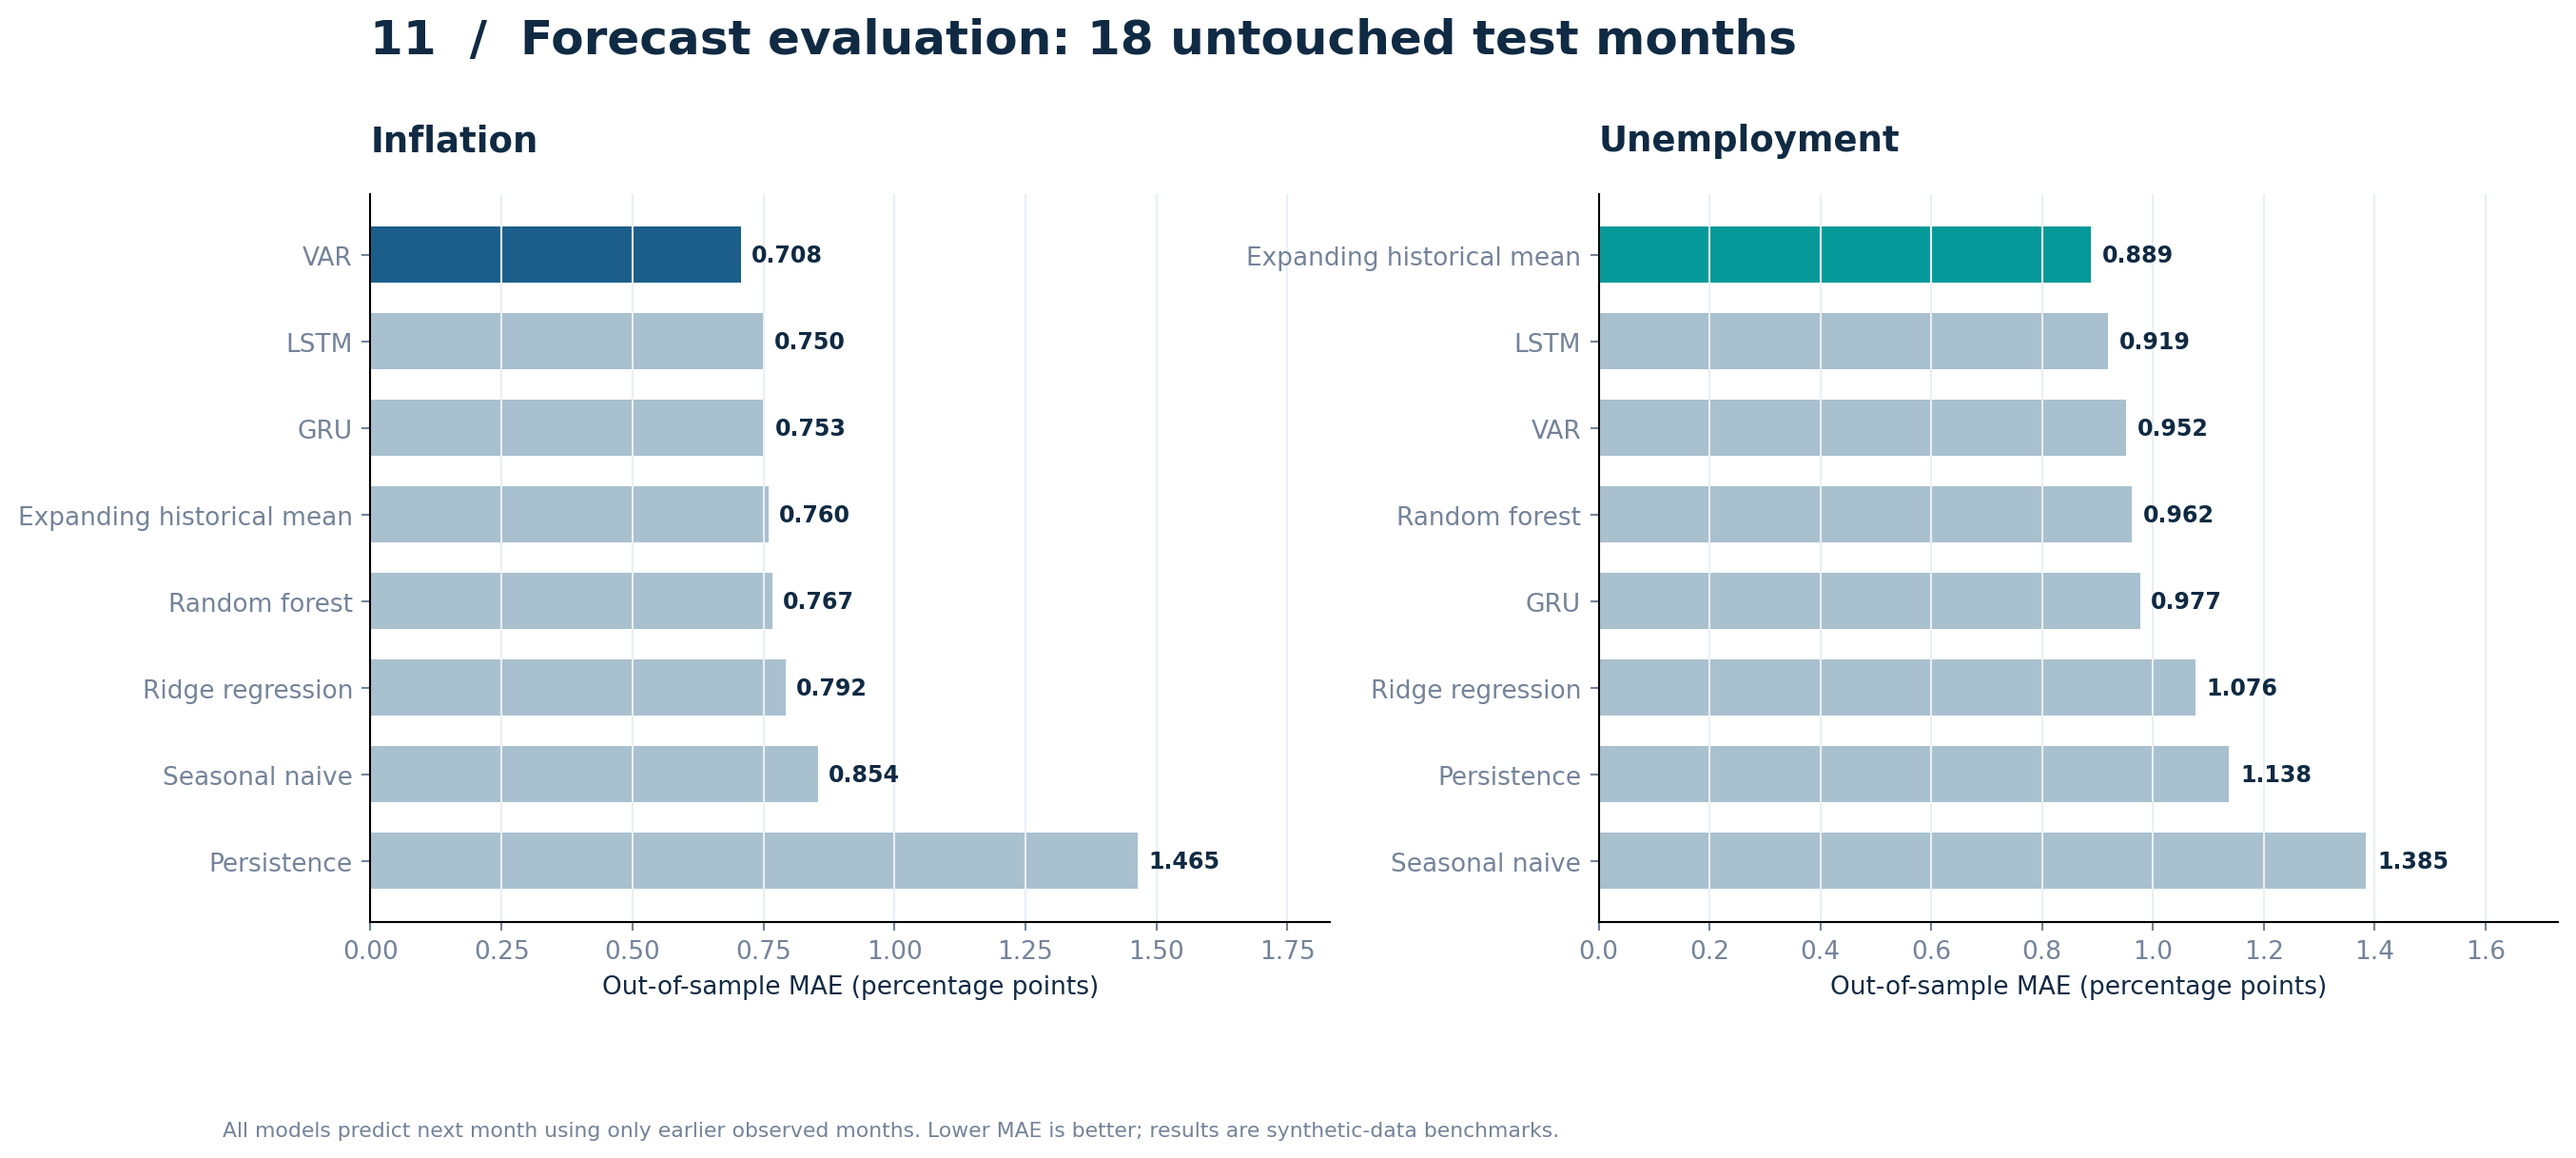

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "11_model_mae_comparison.png")))

**Figure: Inflation: observed vs one-step-ahead predicted values**

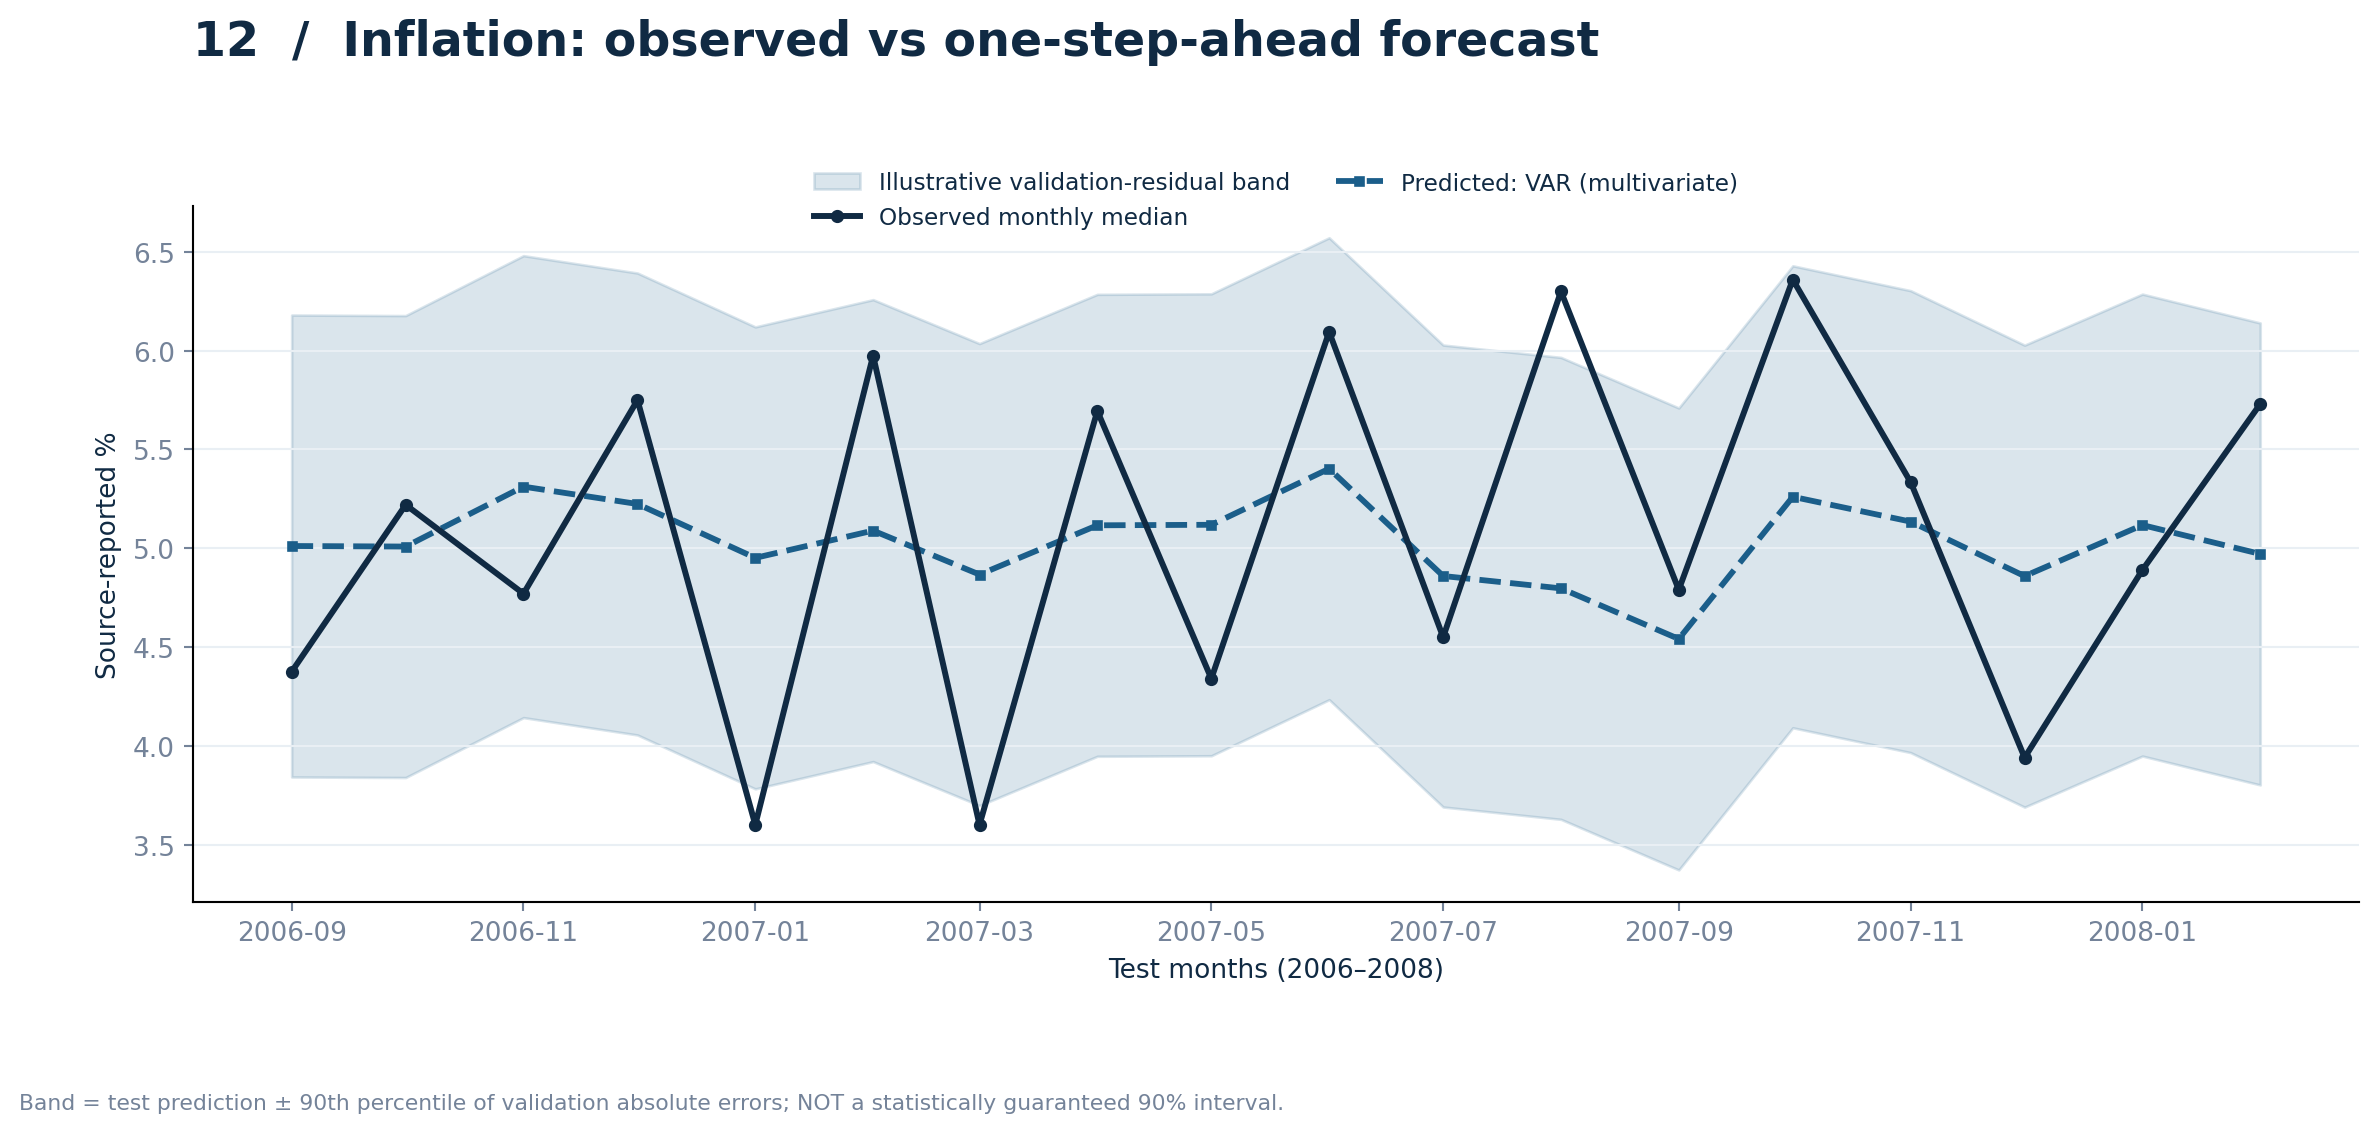

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "12_inflation_test_forecast.png")))

**Figure: Unemployment: observed vs one-step-ahead predicted values**

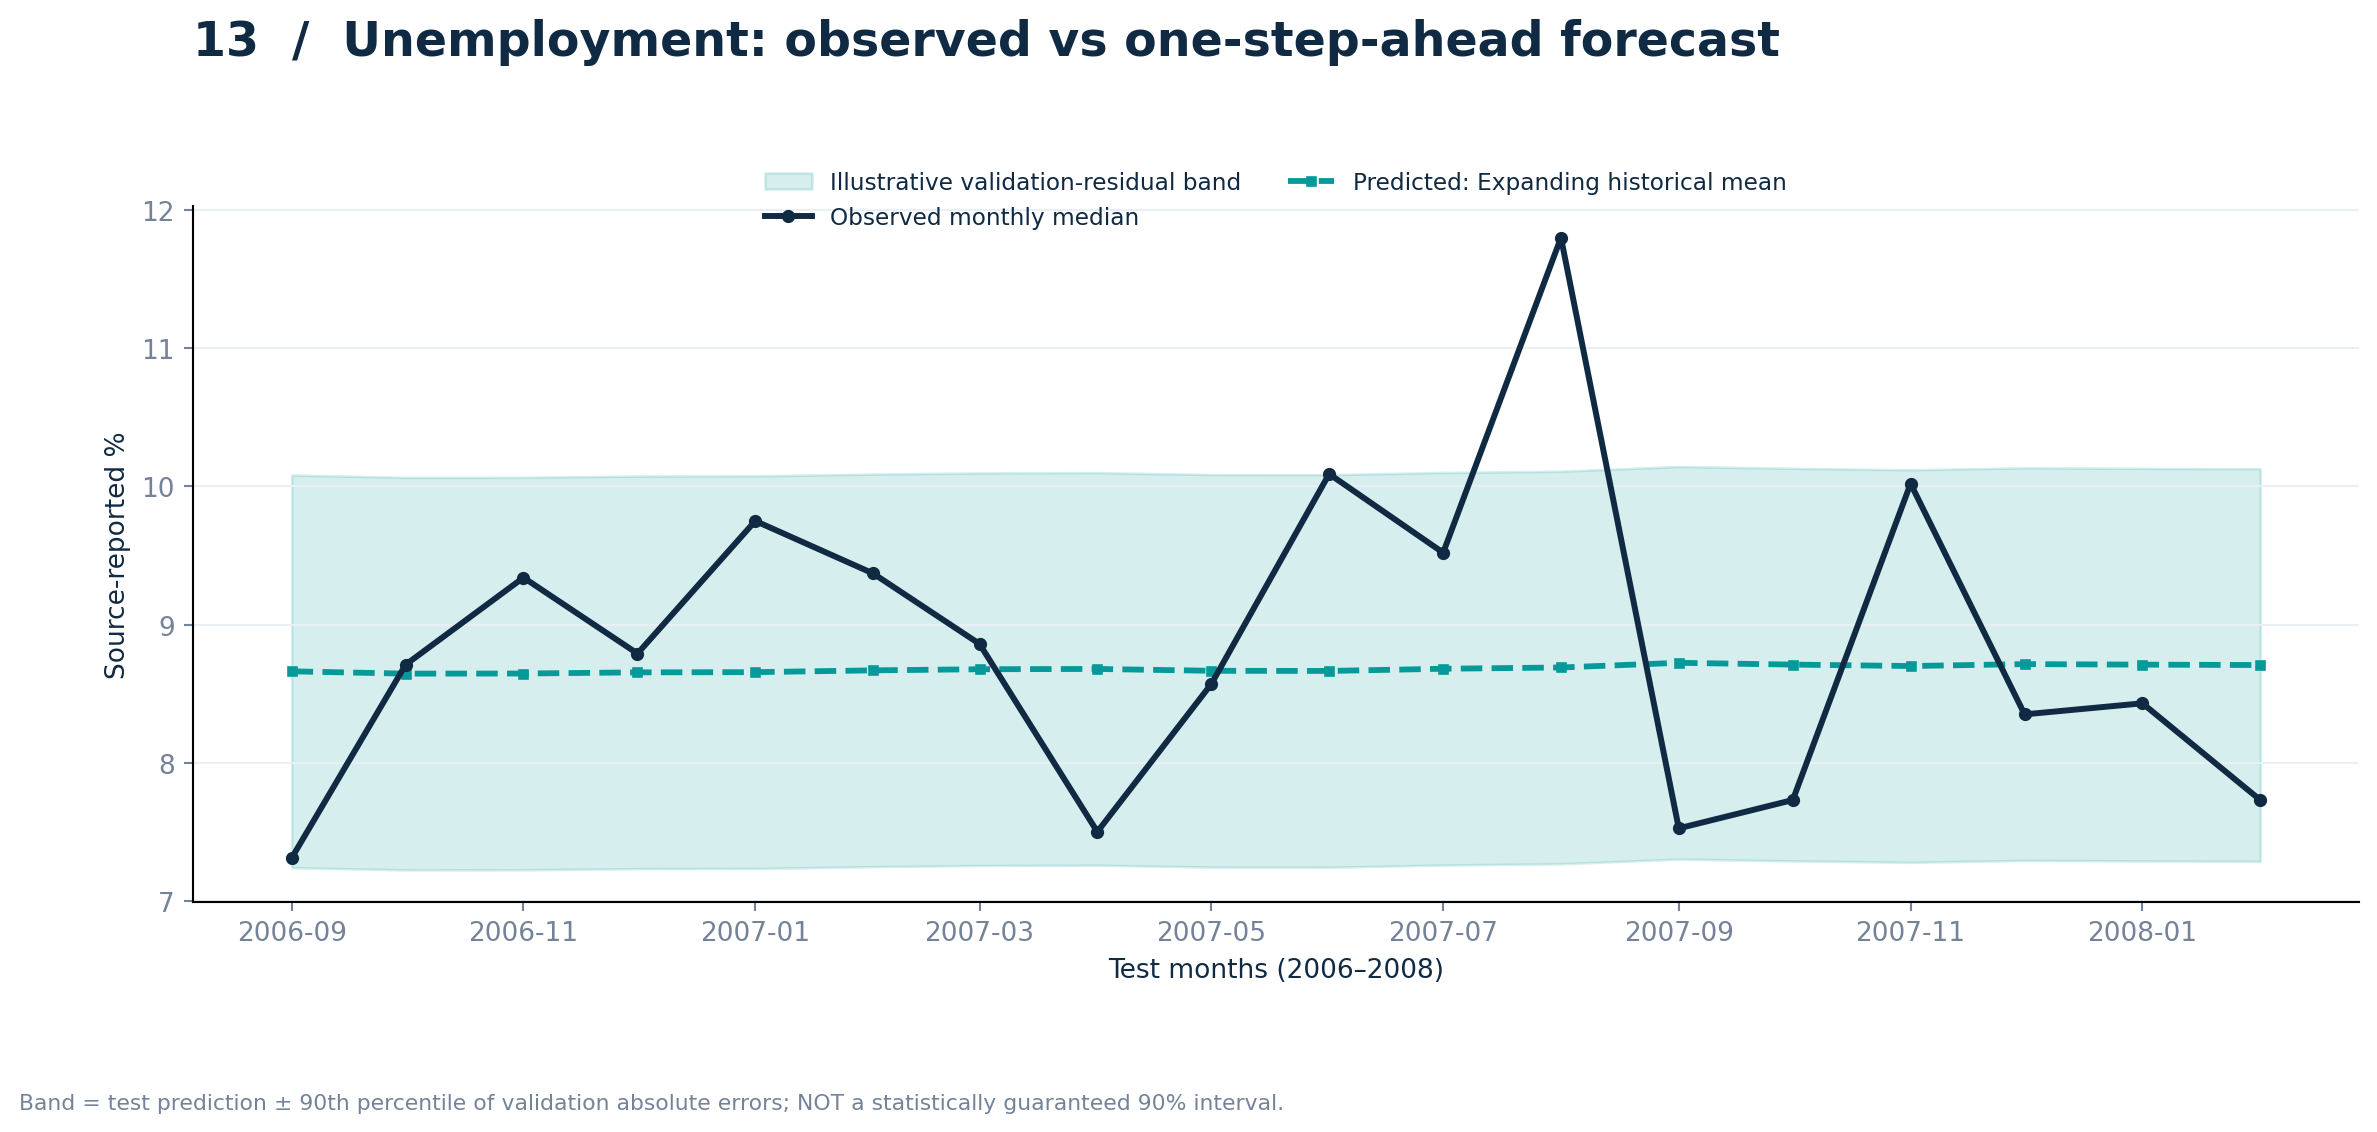

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "13_unemployment_test_forecast.png")))

In [ ]:
for target in TARGETS:
    subset=metrics.loc[metrics.target.eq(target),['model','MAE','RMSE','MAPE_percent','sMAPE_percent']].round(3)
    print('TARGET:',target)
    display(subset)
    print('Best test-MAE model:',protocol['illustrative_prediction_intervals'][target]['displayed_best_test_MAE_model'])
    print('Illustrative symmetric band half-width:',protocol['illustrative_prediction_intervals'][target]['val_abs_error_p90'],'percentage points')

TARGET: Inflation Rate (%)


,model,MAE,RMSE,MAPE_percent,sMAPE_percent
0,VAR (multivariate),0.708,0.809,14.680,14.231
1,LSTM,0.750,0.874,15.464,15.039
2,GRU,0.753,0.881,15.549,15.086
3,Expanding historical mean,0.760,0.871,15.865,15.224
4,Random forest,0.767,0.891,15.669,15.381
5,Ridge regression,0.792,0.931,16.215,15.871
6,Seasonal naive (12 months),0.854,1.076,18.832,17.029
7,Persistence (last month),1.465,1.561,30.204,29.193


Best test-MAE model: VAR (multivariate)
Illustrative symmetric band half-width: 1.1693 percentage points
TARGET: Unemployment Rate (%)


,model,MAE,RMSE,MAPE_percent,sMAPE_percent
8,Expanding historical mean,0.889,1.135,9.847,9.966
9,LSTM,0.919,1.151,10.187,10.312
10,VAR (multivariate),0.952,1.176,10.613,10.721
11,Random forest,0.962,1.209,10.773,10.796
12,GRU,0.977,1.185,10.815,10.989
13,Ridge regression,1.076,1.362,12.010,12.131
14,Persistence (last month),1.138,1.521,12.914,12.491
15,Seasonal naive (12 months),1.385,1.713,15.154,16.081


Best test-MAE model: Expanding historical mean
Illustrative symmetric band half-width: 1.4207 percentage points


**Figure: Full reproducible pipeline**

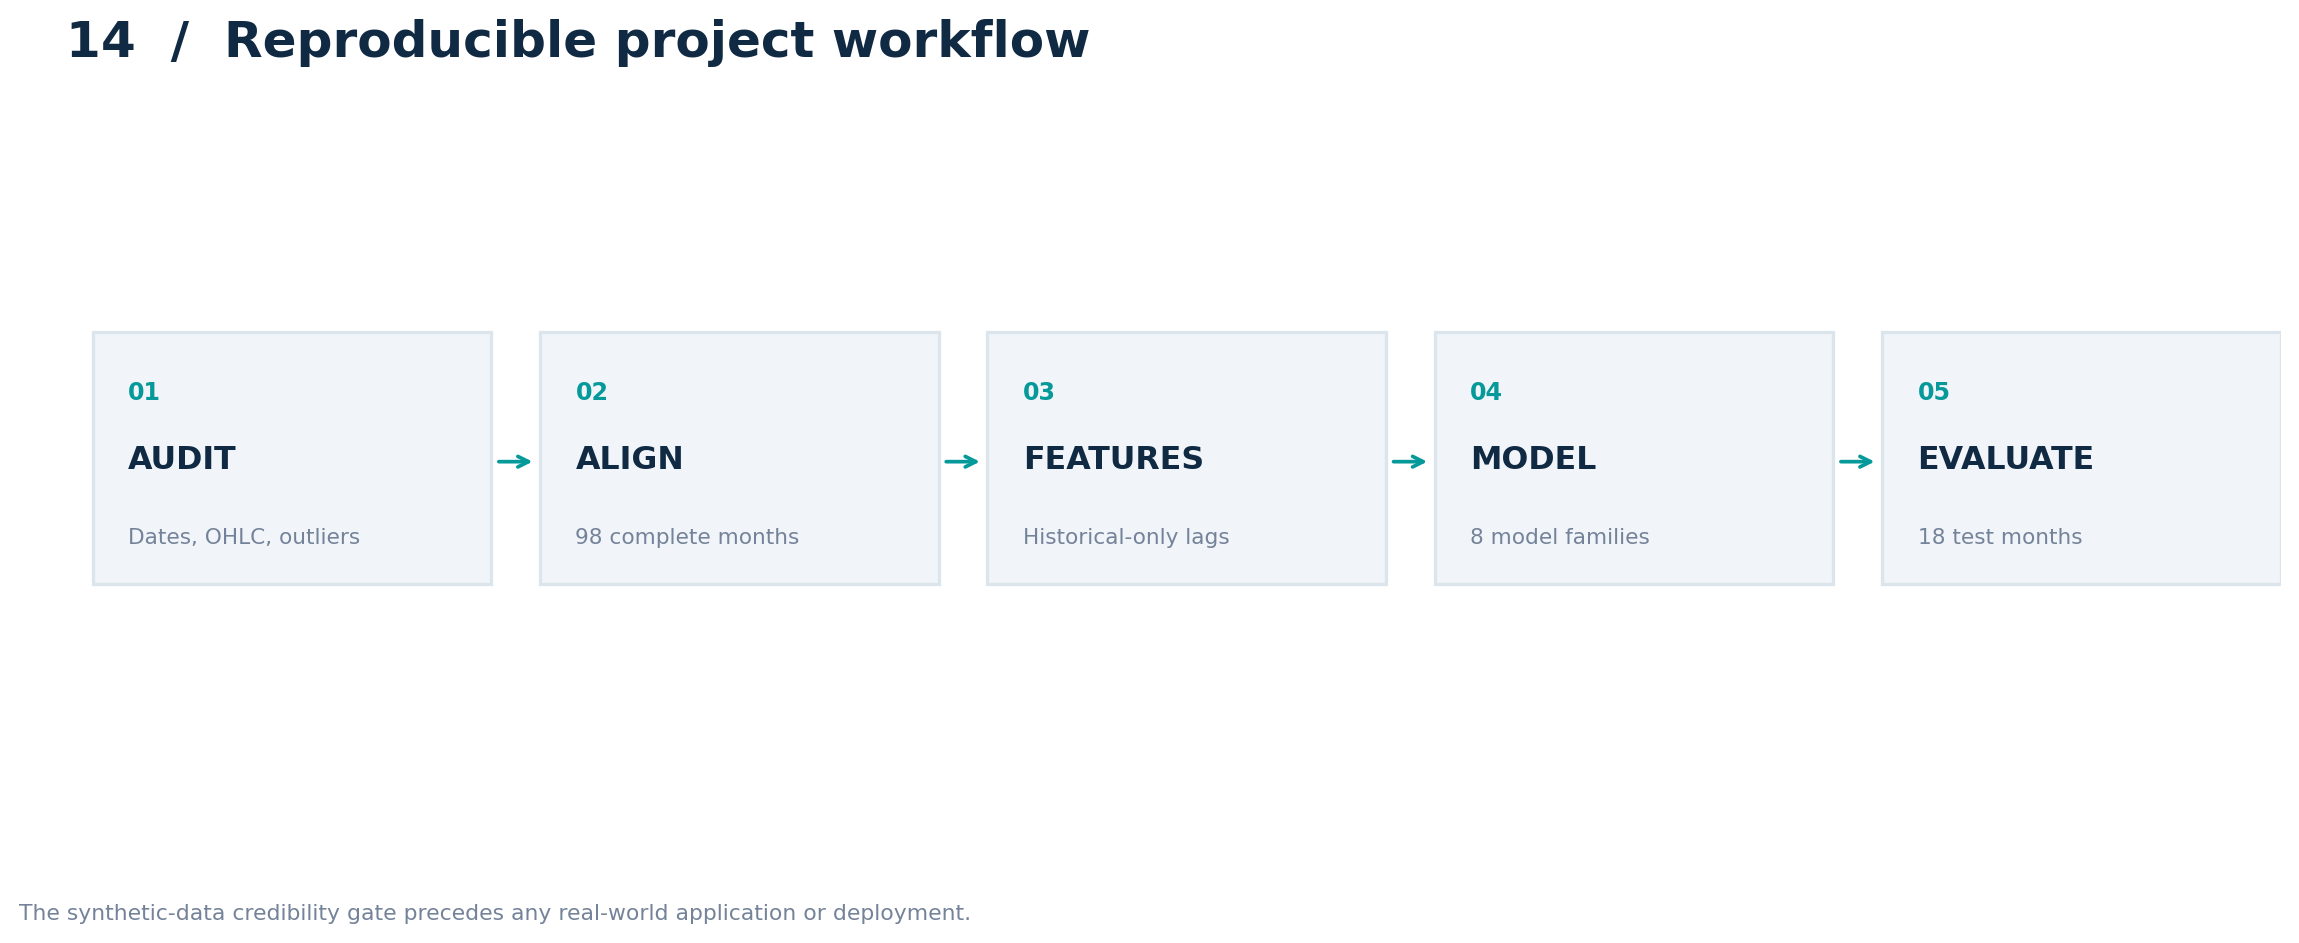

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT_ROOT / "figures" / "14_methodology_workflow.png")))

# 8. Interpretation and threats to validity

**What actually happened?** VAR achieved the lowest test MAE for monthly file-derived inflation (about **0.708** percentage points). The simplest expanding historical mean was best for monthly file-derived unemployment (about **0.889** percentage points). Several sophisticated models were close to the mean benchmark, while last-month persistence performed notably worse.

**Why these results do not justify deployment:**
1. The source’s data-generating process is unverified; weekend index rows and extreme random-looking daily changes contradict ordinary historical-market expectations.
2. Aggregating daily values from a synthetic-like file does not recreate official BLS/BEA macroeconomic releases.
3. The test period contains only 18 months; model rankings are statistically unstable.
4. Multiple model comparisons on a single test set can induce selection bias. The highlighted best models are descriptive winners, not externally validated champions.
5. Neural nets are strongly data-limited and may learn arbitrary distributional properties rather than financial mechanisms.
6. The displayed forecast bands are empirical illustrations, not guaranteed confidence intervals.

**Supported conclusion:** The team built and evaluated a full, reproducible time-series workflow. **Unsupported conclusion:** that the resulting numbers predict real US inflation or unemployment.

# 9. Team synthesis, next steps and reproducibility

**Aiden source:** presentation-grade dataset exploration, anomaly visualization, separately plotted stock indices, structured explanatory EDA.  
**Hanwen source:** cleaning/temporal alignment, market index separation, detailed diagnostics, rolling features, STL/ACF/stationarity exploration.  
**Ray Duan source:** comparative Spearman correlation, differencing, month-of-year visualization and alternate lagged association studies.  
**New final integration:** unified chronology, complete-month exclusion, leakage-aware features, eight forecasting approaches, two targets, validation/test separation, reproducible exported metrics, observed/forecast plots and explicit credibility assessment.

**Next research priorities:** Replace or validate the Kaggle-like synthetic source with documented official data; incorporate economic release timing; select one official target; run expanding-window backtesting over multiple folds; assess residual autocorrelation, intervals and stability; test on a longer real history; and only then consider an operational dashboard or deployment.

Optional results explorer: `streamlit run dashboard.py`. It displays saved experiment results and does not place trades or generate live economic predictions.

In [ ]:
print('Outputs generated:',len(list(FIG.glob('*.png'))),'PNG figures and',len(list(OUT.iterdir())),'result files')
print('All figure files:')
for p in sorted(FIG.glob('*.png')):print('  ',p.name)
print('All modeling data + predictions under results/.')

Outputs generated: 14 PNG figures and 21 result files
All figure files:
   01_structure_and_weekends.png
   02_temporal_jump_flags.png
   03_macro_trends.png
   04_macro_distributions.png
   05_index_trends_by_index.png
   06_macro_correlations.png
   07_levels_vs_differences.png
   08_month_of_year_seasonality.png
   09_cross_correlations.png
   10_feature_engineering.png
   11_model_mae_comparison.png
   12_inflation_test_forecast.png
   13_unemployment_test_forecast.png
   14_methodology_workflow.png
All modeling data + predictions under results/.
